# DASSS Assignment-3
### Name: Shreeya Tapaswi
### Roll No. 31474

## Dataset Description
**UCI Appliances Energy Prediction Dataset**

The dataset used in this project is the Appliances Energy Prediction Dataset obtained from the UCI Machine Learning Repository.

*   **Dataset Source:**
https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction
The dataset contains `19,735 observations and 28 input features`. It is a multivariate time-series dataset containing measurements collected at 10-minute intervals over approximately 4.5 months in a low-energy building.

*  **Collection of Data:**
The household temperature and humidity conditions were collected using a ZigBee wireless sensor network. Energy consumption was recorded using energy meters at 10-minute intervals. Weather information from the nearest airport weather station was also combined with the household measurements.

The main target variable in the original dataset is:

`Appliances` — appliance energy consumption measured in Watt-hours (Wh).

## Import Libraries

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## Download Dataset

In [ ]:
!wget -q "https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip"

!unzip -o "appliances+energy+prediction.zip"

print("Dataset downloaded and extracted successfully!")

Archive:  appliances+energy+prediction.zip
 extracting: energydata_complete.csv  
Dataset downloaded and extracted successfully!


## Check Files

In [ ]:
import os

print(os.listdir())

['.config', 'energydata_complete.csv', 'appliances+energy+prediction.zip', 'sample_data']


## Load Dataset

In [ ]:
df = pd.read_csv("energydata_complete.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


### Number of Rows and Columns

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 19735
Number of columns: 29


## Column Names

In [ ]:
print("Dataset Columns:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Dataset Columns:

1 : date
2 : Appliances
3 : lights
4 : T1
5 : RH_1
6 : T2
7 : RH_2
8 : T3
9 : RH_3
10 : T4
11 : RH_4
12 : T5
13 : RH_5
14 : T6
15 : RH_6
16 : T7
17 : RH_7
18 : T8
19 : RH_8
20 : T9
21 : RH_9
22 : T_out
23 : Press_mm_hg
24 : RH_out
25 : Windspeed
26 : Visibility
27 : Tdewpoint
28 : rv1
29 : rv2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [ ]:
print(df.dtypes)

date            object
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object


In [ ]:
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [ ]:
df.nunique()

,0
date,19735
Appliances,92
lights,8
T1,722
RH_1,2547
T2,1650
RH_2,3376
T3,1426
RH_3,2618
T4,1390


In [ ]:
missing_count = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing_count.index,
    "Missing Values": missing_count.values,
    "Missing Percentage": (
        missing_count.values / len(df) * 100
    )
})

missing_table

,Column,Missing Values,Missing Percentage
0,date,0,0.0
1,Appliances,0,0.0
2,lights,0,0.0
3,T1,0,0.0
4,RH_1,0,0.0
5,T2,0,0.0
6,RH_2,0,0.0
7,T3,0,0.0
8,RH_3,0,0.0
9,T4,0,0.0


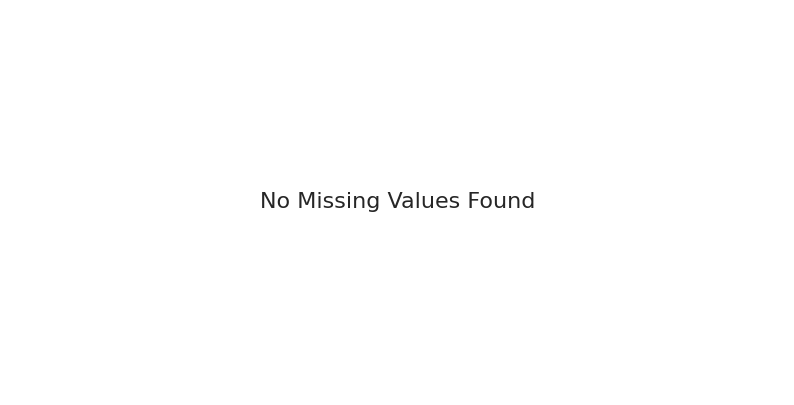

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0]

plt.figure(figsize=(10, 5))

if len(missing) > 0:

    missing.plot(kind="bar")

    plt.xlabel("Features")
    plt.ylabel("Number of Missing Values")
    plt.title("Missing Values by Feature")

    plt.xticks(rotation=45)

else:

    plt.text(
        0.5,
        0.5,
        "No Missing Values Found",
        ha="center",
        va="center",
        fontsize=16
    )

    plt.axis("off")

plt.show()

## Duplicate Records

In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## Unique vs Duplicate Graph

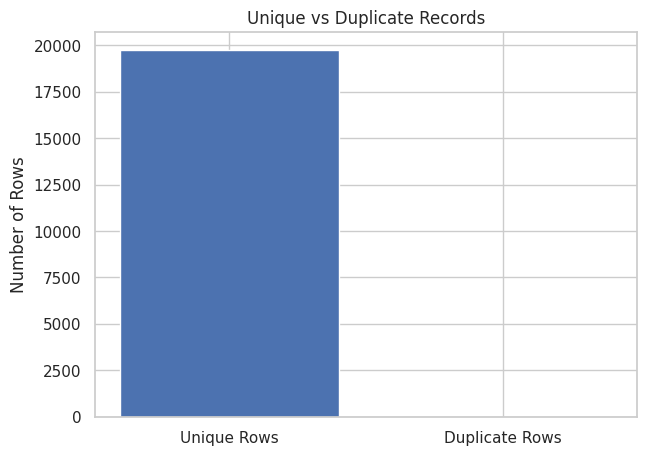

In [ ]:
duplicate_count = df.duplicated().sum()
unique_count = len(df) - duplicate_count

plt.figure(figsize=(7, 5))

plt.bar(
    ["Unique Rows", "Duplicate Rows"],
    [unique_count, duplicate_count]
)

plt.ylabel("Number of Rows")
plt.title("Unique vs Duplicate Records")

plt.show()

## Remove Duplicates

In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (19735, 29)


## Convert Date

In [ ]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].dtype)
print(df["date"].head())

datetime64[ns]
0   2016-01-11 17:00:00
1   2016-01-11 17:10:00
2   2016-01-11 17:20:00
3   2016-01-11 17:30:00
4   2016-01-11 17:40:00
Name: date, dtype: datetime64[ns]


## Extract Date Features

In [ ]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["hour"] = df["date"].dt.hour
df["minute"] = df["date"].dt.minute
df["day_of_week"] = df["date"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Tdewpoint,rv1,rv2,year,month,day,hour,minute,day_of_week,is_weekend
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,5.3,13.275433,13.275433,2016,1,11,17,0,0,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,5.2,18.606195,18.606195,2016,1,11,17,10,0,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,5.1,28.642668,28.642668,2016,1,11,17,20,0,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,5.0,45.410389,45.410389,2016,1,11,17,30,0,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,4.9,10.084097,10.084097,2016,1,11,17,40,0,0


## Create Time Period

In [ ]:
def get_time_period(hour):

    if 0 <= hour < 6:
        return "Night"

    elif 6 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 18:
        return "Afternoon"

    else:
        return "Evening"


df["time_period"] = df["hour"].apply(
    get_time_period
)

df["time_period"].value_counts()

,count
time_period,
Afternoon,4938
Evening,4933
Night,4932
Morning,4932


## Energy Consumption Distribution

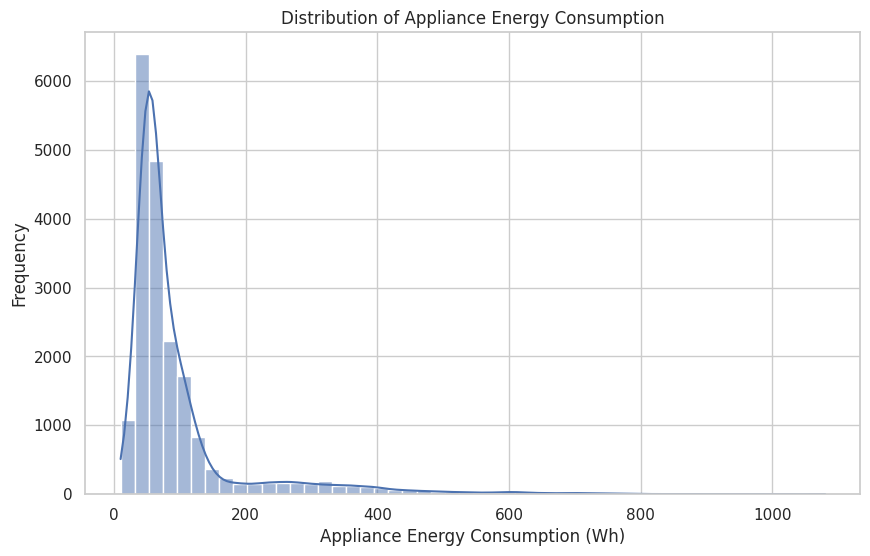

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Appliances"],
    bins=50,
    kde=True
)

plt.xlabel("Appliance Energy Consumption (Wh)")
plt.ylabel("Frequency")

plt.title(
    "Distribution of Appliance Energy Consumption"
)

plt.show()

## Box Plot / Outlier Analysis

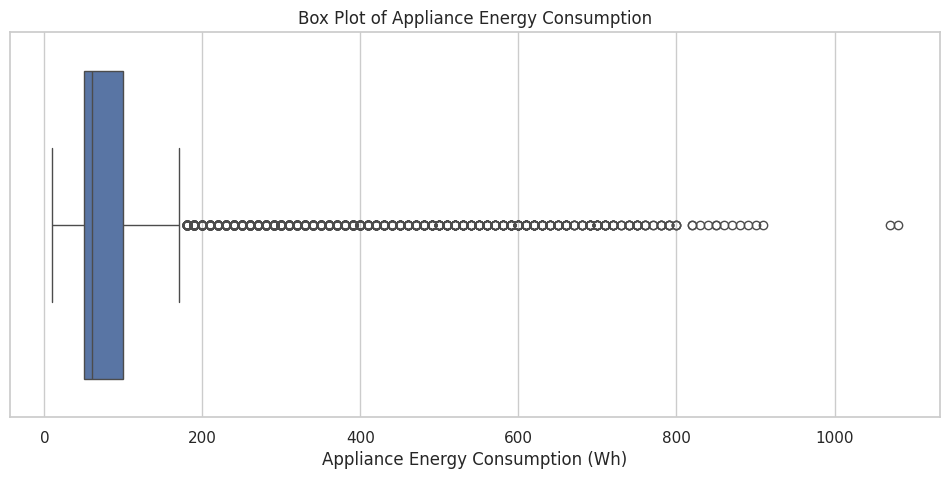

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df["Appliances"]
)

plt.xlabel(
    "Appliance Energy Consumption (Wh)"
)

plt.title(
    "Box Plot of Appliance Energy Consumption"
)

plt.show()

## Calculate Outliers

In [ ]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Appliances"] < lower_bound) |
    (df["Appliances"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Number of Outliers:", len(outliers))

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower Bound: -25.0
Upper Bound: 175.0
Number of Outliers: 2138


## Daily Energy Consumption

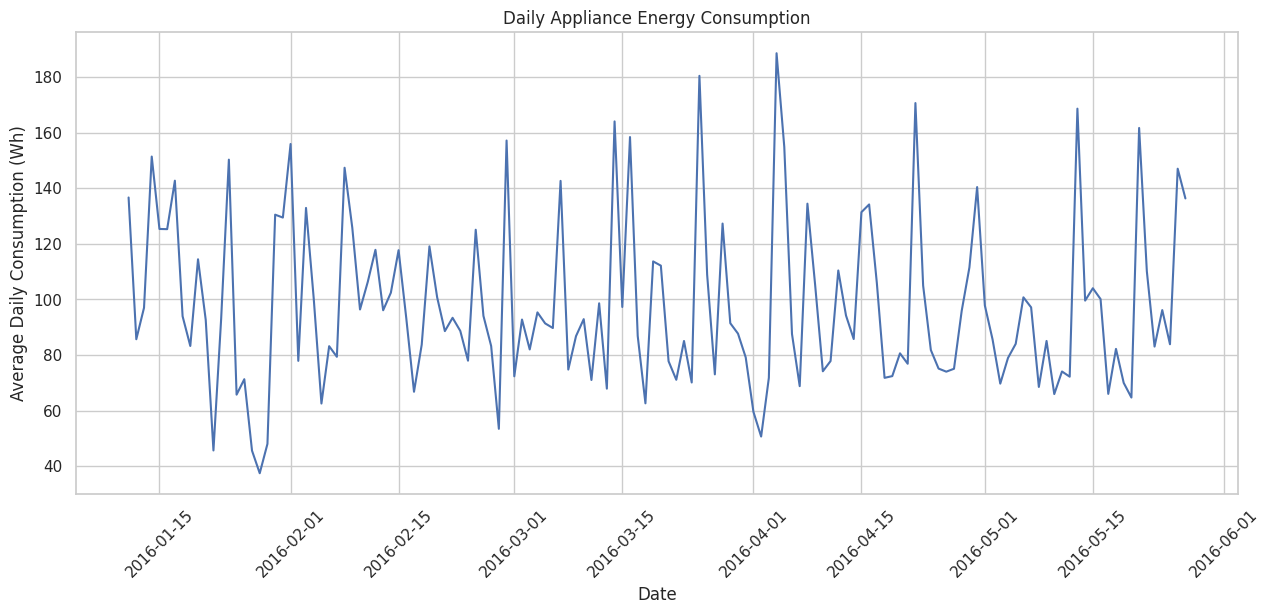

In [ ]:
daily_consumption = (
    df.set_index("date")
      ["Appliances"]
      .resample("D")
      .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    daily_consumption.index,
    daily_consumption.values
)

plt.xlabel("Date")
plt.ylabel(
    "Average Daily Consumption (Wh)"
)

plt.title(
    "Daily Appliance Energy Consumption"
)

plt.xticks(rotation=45)

plt.show()

## Hourly Energy Consumption

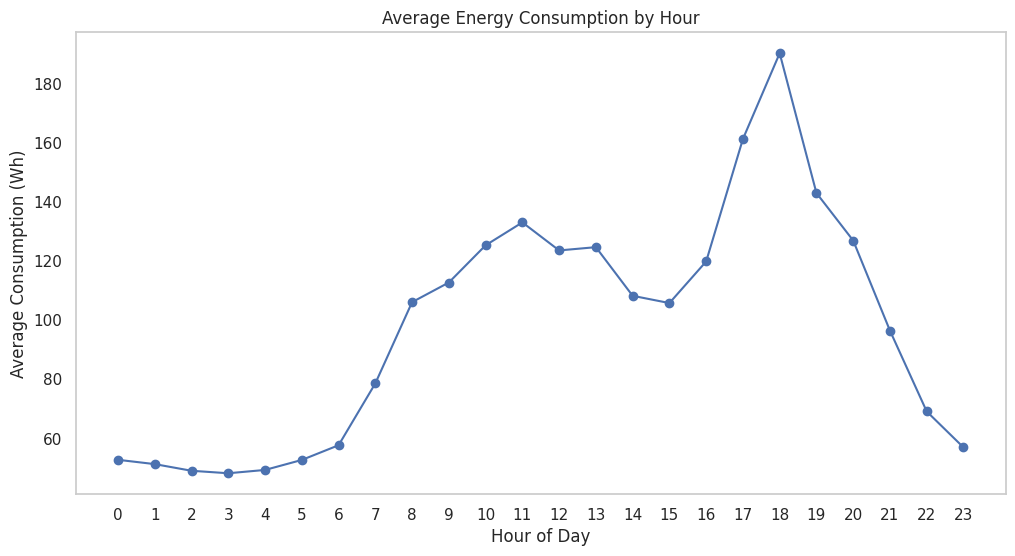

In [ ]:
hourly = df.groupby(
    "hour"
)["Appliances"].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    hourly.index,
    hourly.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (Wh)")

plt.title(
    "Average Energy Consumption by Hour"
)

plt.xticks(range(24))

plt.grid()

plt.show()

## Median Consumption by Hour

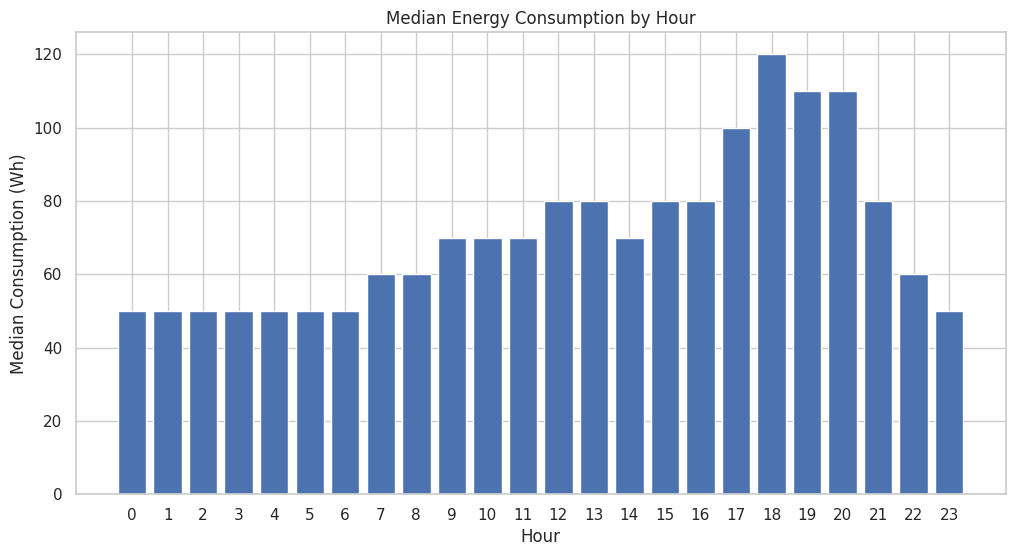

In [ ]:
hourly_median = df.groupby(
    "hour"
)["Appliances"].median()

plt.figure(figsize=(12, 6))

plt.bar(
    hourly_median.index,
    hourly_median.values
)

plt.xlabel("Hour")
plt.ylabel("Median Consumption (Wh)")

plt.title(
    "Median Energy Consumption by Hour"
)

plt.xticks(range(24))

plt.show()

## Day of Week Analysis

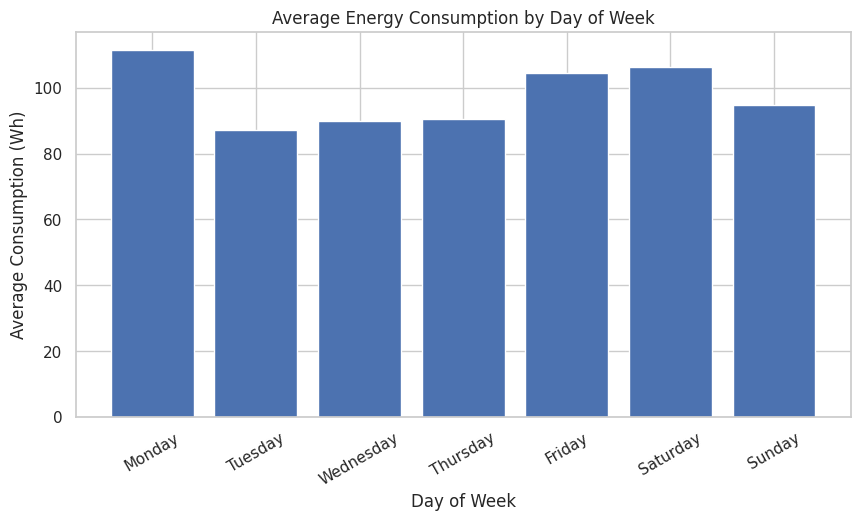

In [ ]:
day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_consumption = (
    df.groupby("day_of_week")
      ["Appliances"]
      .mean()
)

plt.figure(figsize=(10, 5))

plt.bar(
    day_names,
    day_consumption.values
)

plt.xlabel("Day of Week")
plt.ylabel("Average Consumption (Wh)")

plt.title(
    "Average Energy Consumption by Day of Week"
)

plt.xticks(rotation=30)

plt.show()

## Weekday vs Weekend

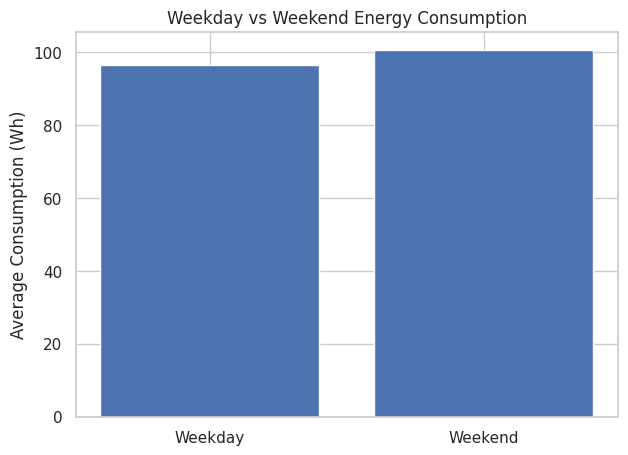

In [ ]:
weekend_consumption = (
    df.groupby("is_weekend")
      ["Appliances"]
      .mean()
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Weekday", "Weekend"],
    weekend_consumption.values
)

plt.ylabel(
    "Average Consumption (Wh)"
)

plt.title(
    "Weekday vs Weekend Energy Consumption"
)

plt.show()

## Time Period Analysis

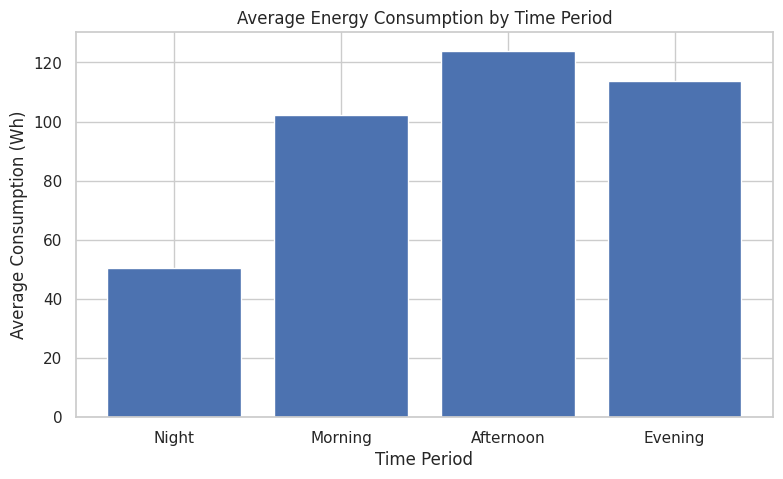

In [ ]:
period_order = [
    "Night",
    "Morning",
    "Afternoon",
    "Evening"
]

period_consumption = (
    df.groupby("time_period")
      ["Appliances"]
      .mean()
      .reindex(period_order)
)

plt.figure(figsize=(9, 5))

plt.bar(
    period_consumption.index,
    period_consumption.values
)

plt.xlabel("Time Period")
plt.ylabel("Average Consumption (Wh)")

plt.title(
    "Average Energy Consumption by Time Period"
)

plt.show()

## Temperature vs Energy

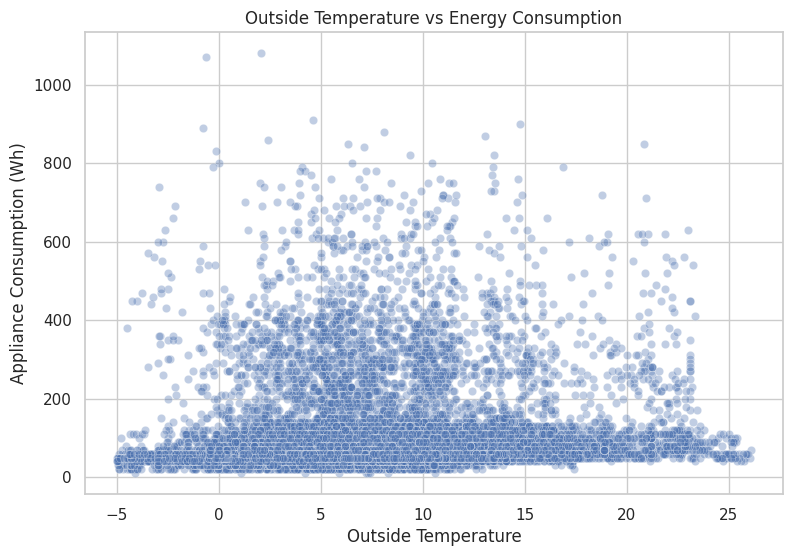

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="T_out",
    y="Appliances",
    alpha=0.35
)

plt.xlabel("Outside Temperature")
plt.ylabel("Appliance Consumption (Wh)")

plt.title(
    "Outside Temperature vs Energy Consumption"
)

plt.show()

## Humidity vs Energy

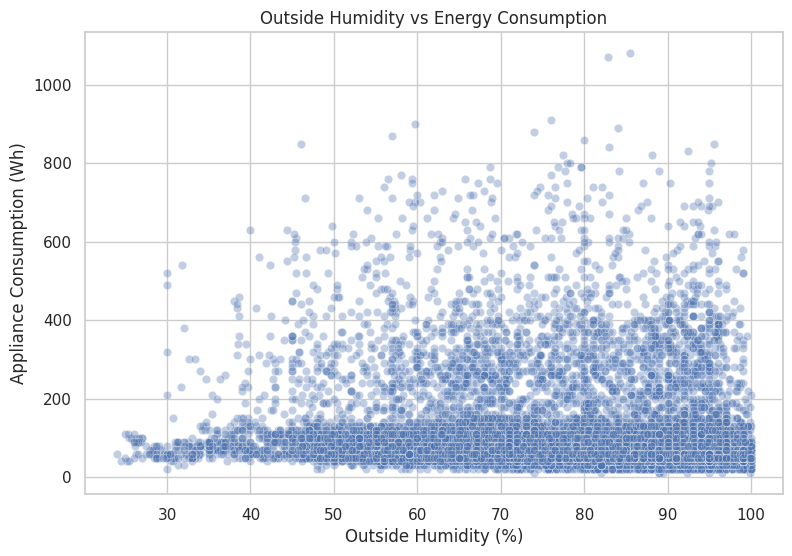

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="RH_out",
    y="Appliances",
    alpha=0.35
)

plt.xlabel("Outside Humidity (%)")
plt.ylabel("Appliance Consumption (Wh)")

plt.title(
    "Outside Humidity vs Energy Consumption"
)

plt.show()

## Wind Speed vs Energy

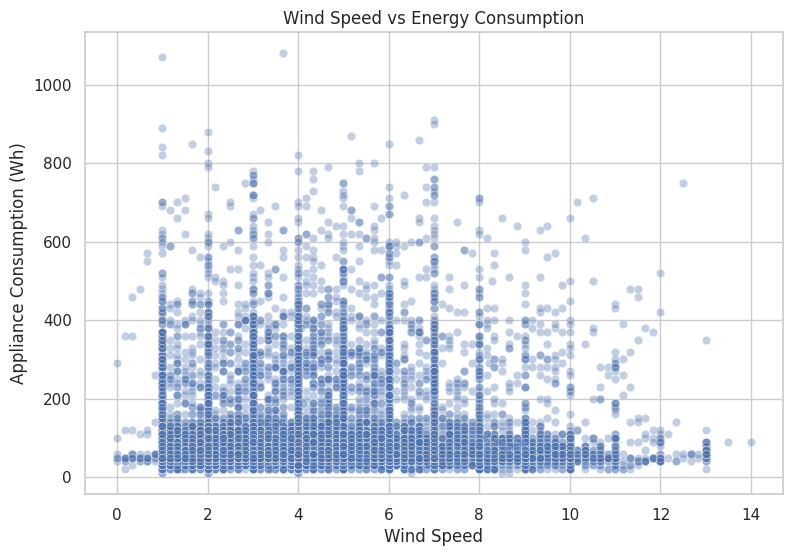

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Windspeed",
    y="Appliances",
    alpha=0.35
)

plt.xlabel("Wind Speed")
plt.ylabel("Appliance Consumption (Wh)")

plt.title(
    "Wind Speed vs Energy Consumption"
)

plt.show()

## Pairplot

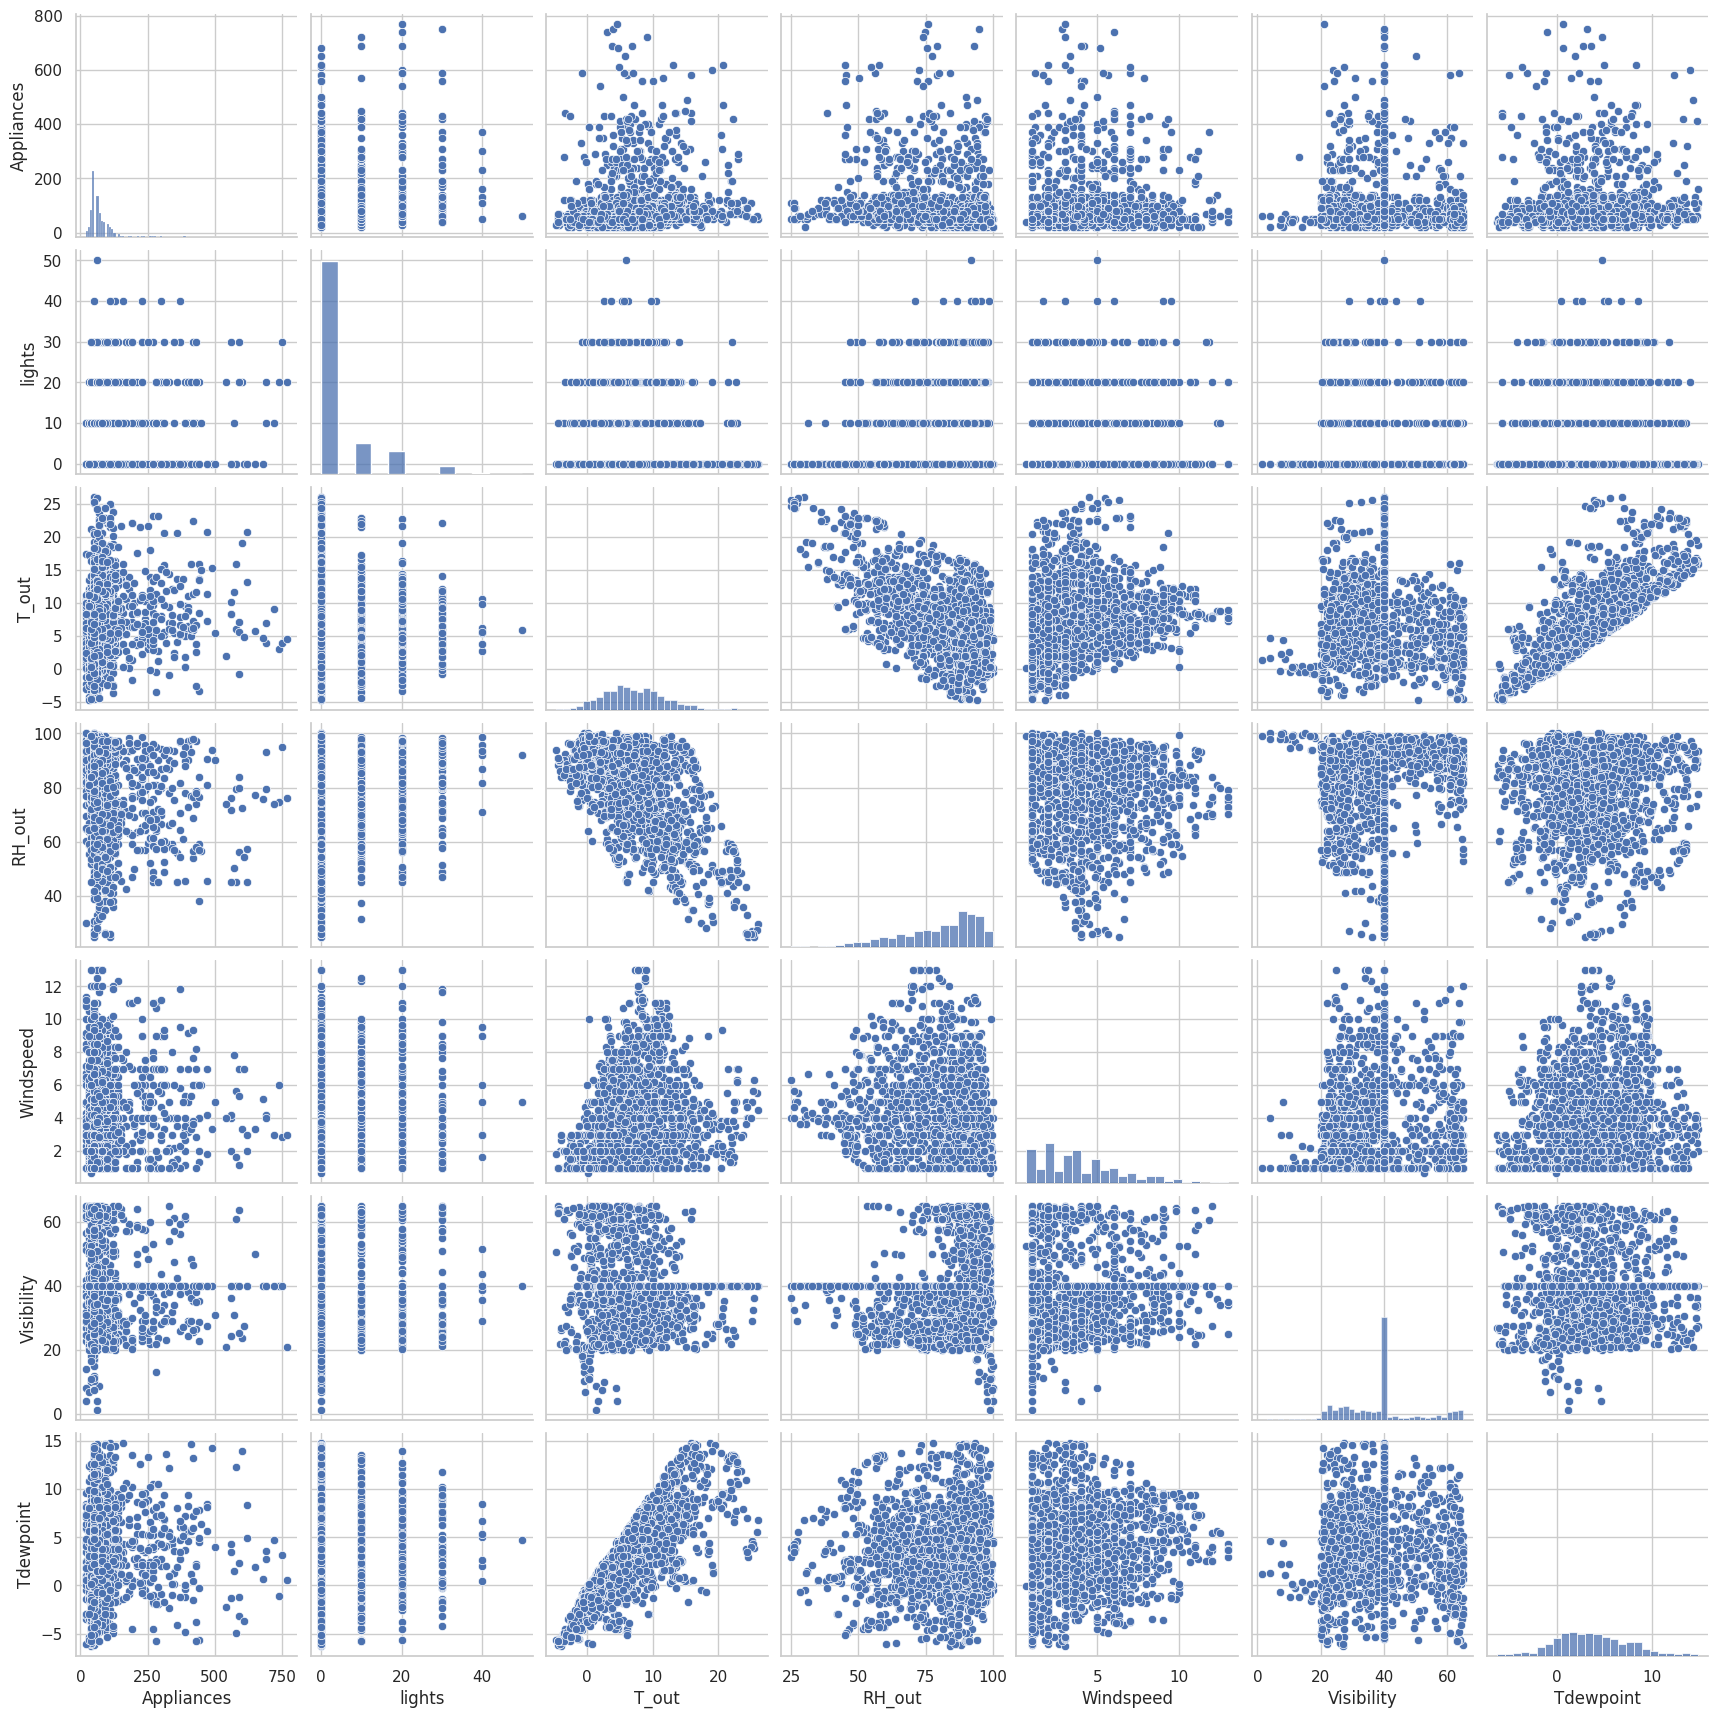

In [ ]:
pair_features = [
    "Appliances",
    "lights",
    "T_out",
    "RH_out",
    "Windspeed",
    "Visibility",
    "Tdewpoint"
]

pair_data = df[
    pair_features
].sample(
    min(2000, len(df)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind="hist"
)

plt.show()

## Correlation Heatmap

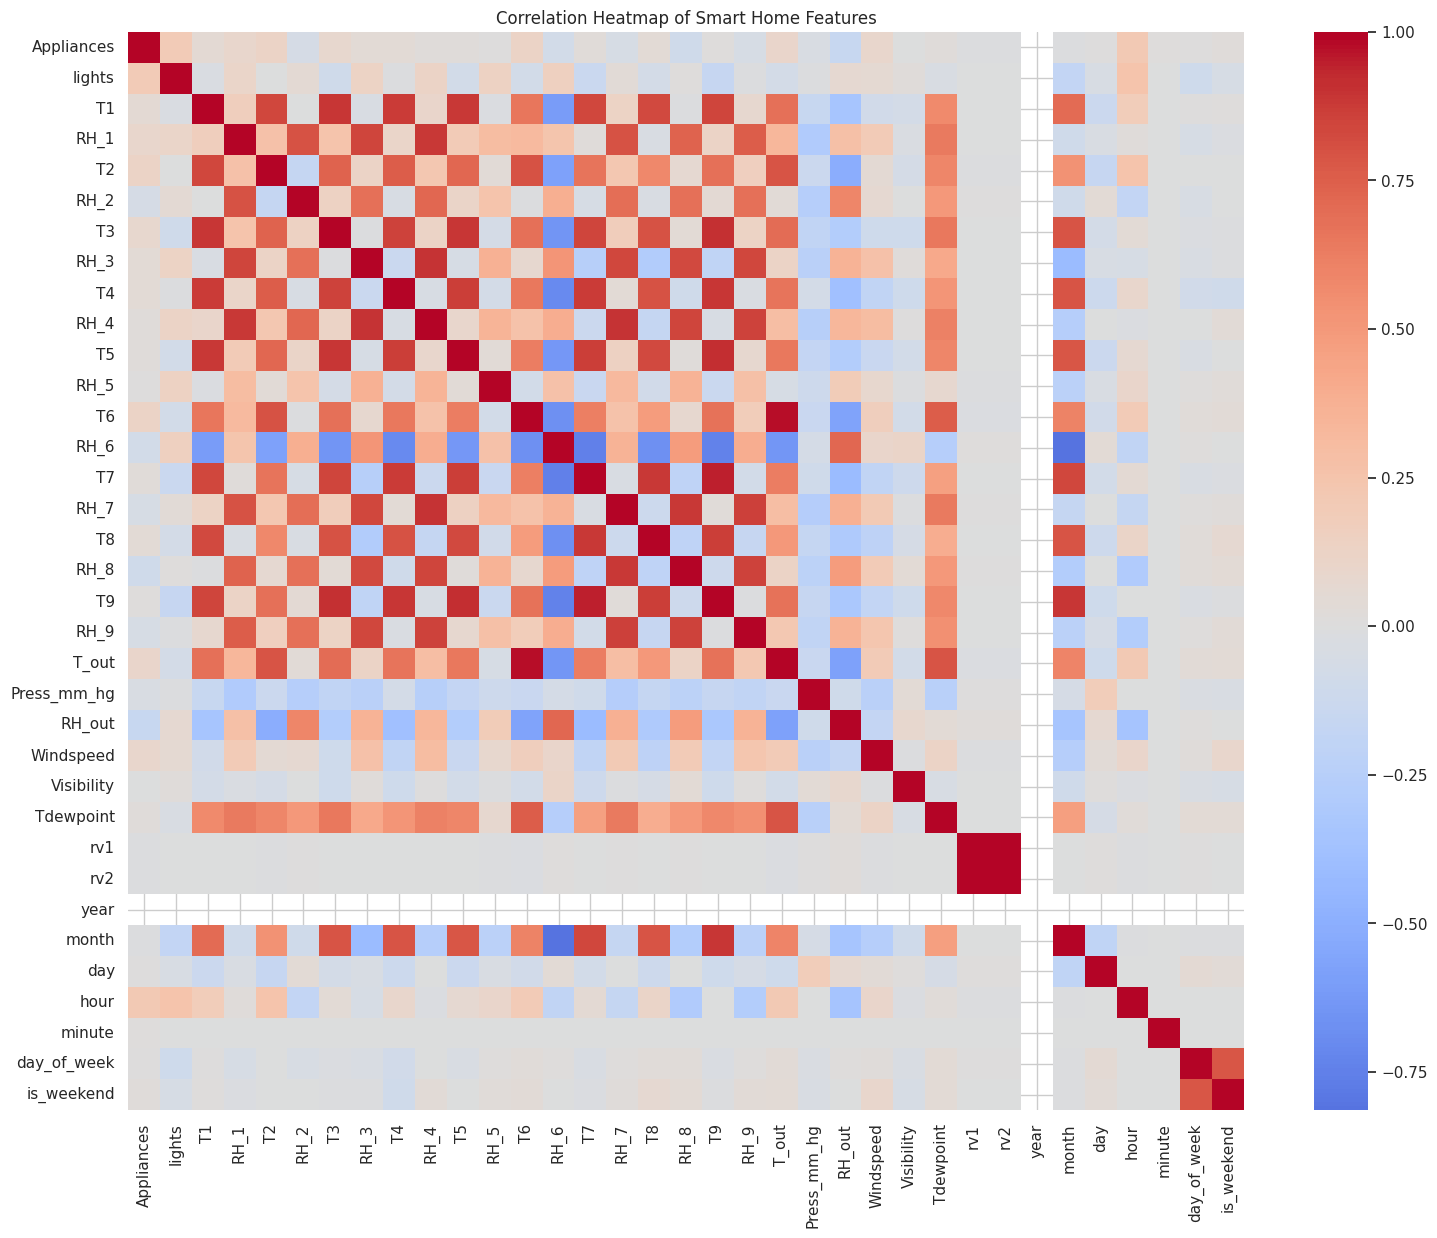

In [ ]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Heatmap of Smart Home Features"
)

plt.show()

## Top Correlated Features

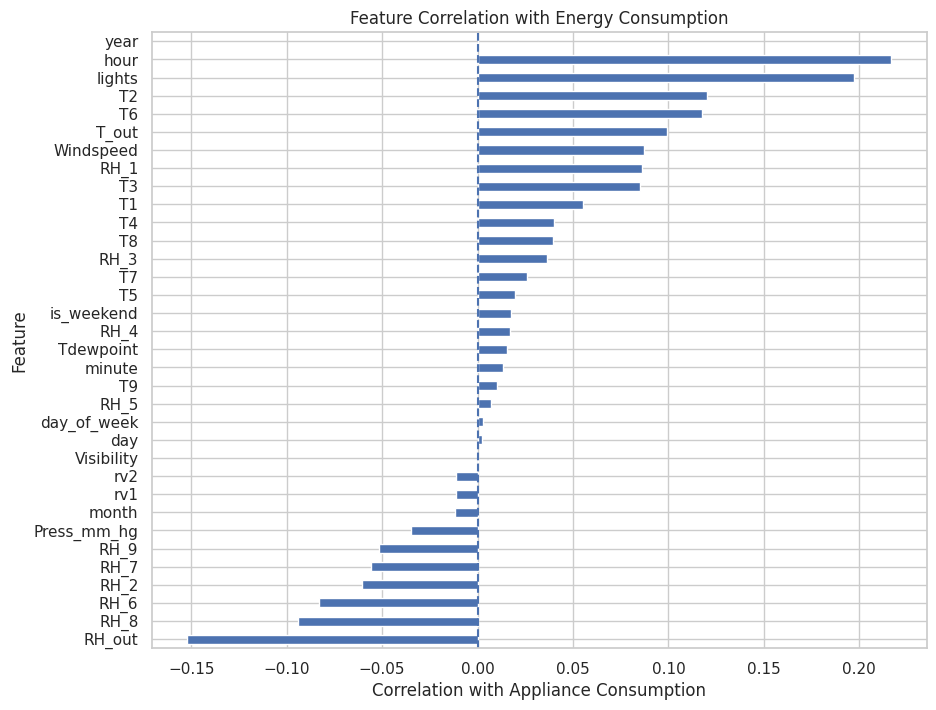

In [ ]:
correlations = (
    numeric_df
    .corr()["Appliances"]
    .drop("Appliances")
    .sort_values()
)

plt.figure(figsize=(10, 8))

correlations.plot(
    kind="barh"
)

plt.xlabel(
    "Correlation with Appliance Consumption"
)

plt.ylabel("Feature")

plt.title(
    "Feature Correlation with Energy Consumption"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.show()

## Top 10 Correlated Features

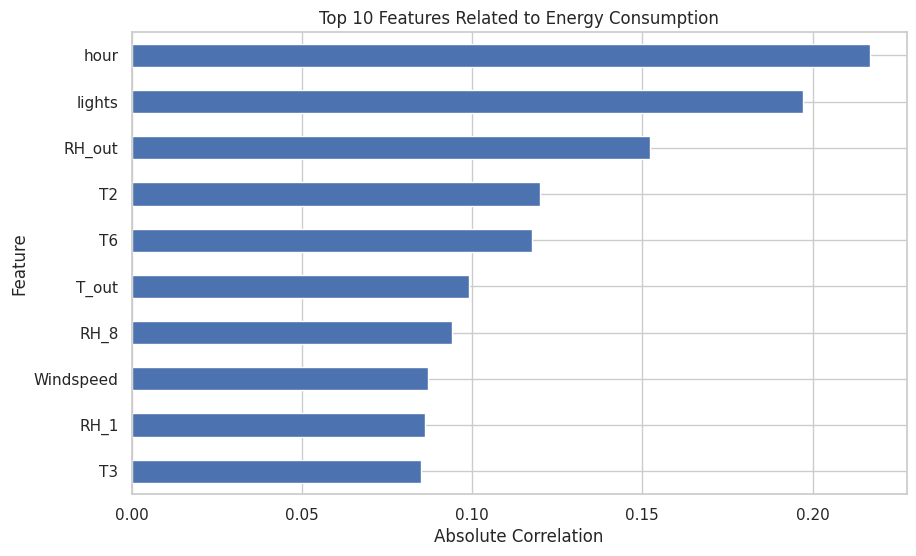

In [ ]:
top_features = (
    numeric_df
    .corr()["Appliances"]
    .drop("Appliances")
    .abs()
    .sort_values(
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

top_features.sort_values().plot(
    kind="barh"
)

plt.xlabel("Absolute Correlation")
plt.ylabel("Feature")

plt.title(
    "Top 10 Features Related to Energy Consumption"
)

plt.show()

## Create Energy Classes

In [ ]:
low_threshold = df["Appliances"].quantile(0.33)
high_threshold = df["Appliances"].quantile(0.66)

print(
    "Low threshold:",
    low_threshold
)

print(
    "High threshold:",
    high_threshold
)

Low threshold: 50.0
High threshold: 80.0


## Assign Energy Classes

In [ ]:
def classify_energy(value):

    if value <= low_threshold:
        return 0

    elif value <= high_threshold:
        return 1

    else:
        return 2


df["Energy_Class"] = df[
    "Appliances"
].apply(
    classify_energy
)

class_names = {
    0: "Low",
    1: "Medium",
    2: "High"
}

df["Energy_Label"] = df[
    "Energy_Class"
].map(class_names)

df[
    [
        "Appliances",
        "Energy_Class",
        "Energy_Label"
    ]
].head(20)

,Appliances,Energy_Class,Energy_Label
0,60,1,Medium
1,60,1,Medium
2,50,0,Low
3,50,0,Low
4,60,1,Medium
5,50,0,Low
6,60,1,Medium
7,60,1,Medium
8,60,1,Medium
9,70,1,Medium


## Class Distribution

In [ ]:
print(
    df["Energy_Label"]
    .value_counts()
)

print("\nPercentages:")

print(
    df["Energy_Label"]
    .value_counts(
        normalize=True
    ) * 100
)

Energy_Label
Low       7462
High      6226
Medium    6047
Name: count, dtype: int64

Percentages:
Energy_Label
Low       37.810996
High      31.548011
Medium    30.640993
Name: proportion, dtype: float64


## Energy Class Graph

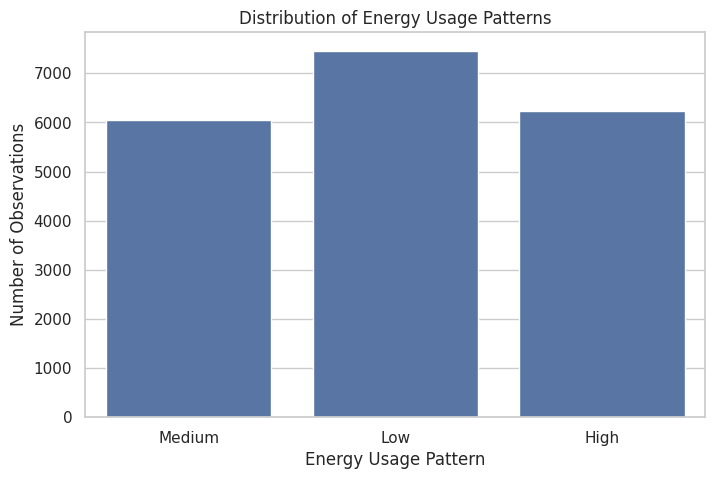

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Energy_Label"
)

plt.xlabel(
    "Energy Usage Pattern"
)

plt.ylabel(
    "Number of Observations"
)

plt.title(
    "Distribution of Energy Usage Patterns"
)

plt.show()

## Energy Classes by Hour

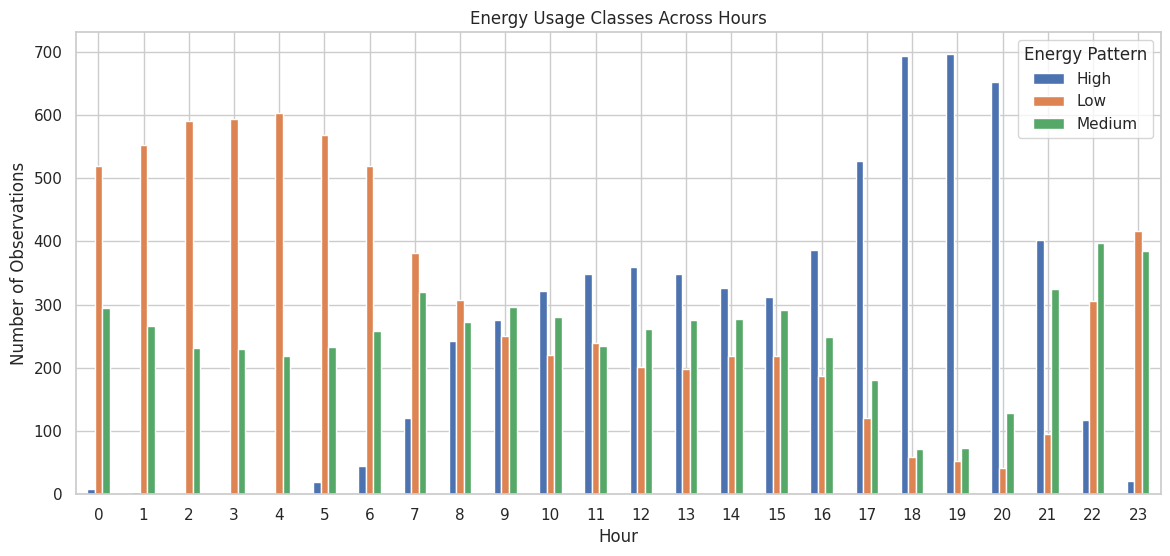

In [ ]:
hour_class = pd.crosstab(
    df["hour"],
    df["Energy_Label"]
)

hour_class.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.xlabel("Hour")
plt.ylabel("Number of Observations")

plt.title(
    "Energy Usage Classes Across Hours"
)

plt.xticks(rotation=0)

plt.legend(
    title="Energy Pattern"
)

plt.show()

## Energy Classes by Day

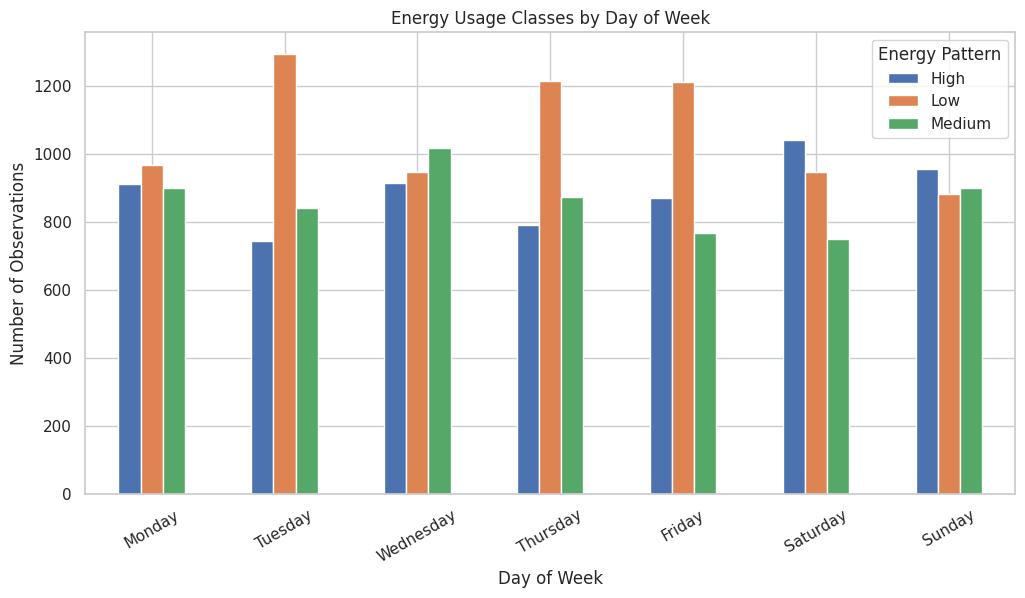

In [ ]:
day_class = pd.crosstab(
    df["day_of_week"],
    df["Energy_Label"]
)

day_class.index = day_names

day_class.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Observations")

plt.title(
    "Energy Usage Classes by Day of Week"
)

plt.xticks(rotation=30)

plt.legend(
    title="Energy Pattern"
)

plt.show()

## Energy Class vs Temperature

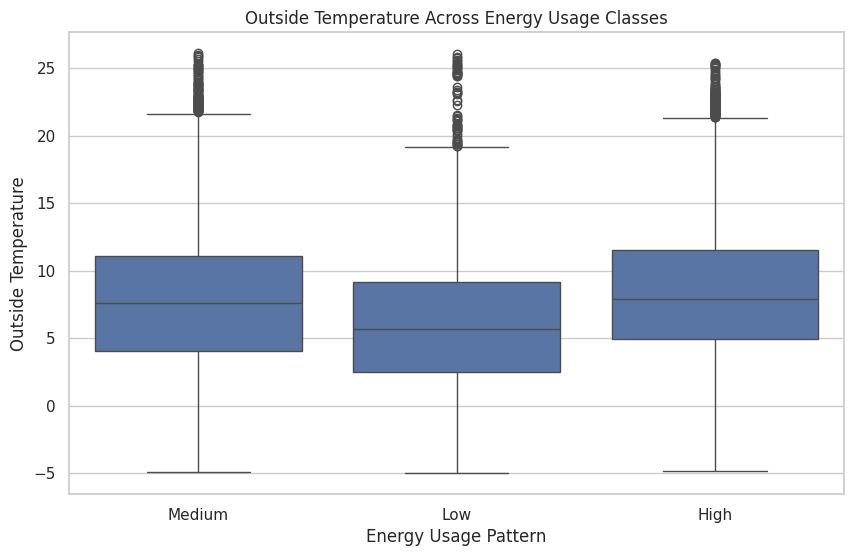

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Energy_Label",
    y="T_out"
)

plt.xlabel(
    "Energy Usage Pattern"
)

plt.ylabel(
    "Outside Temperature"
)

plt.title(
    "Outside Temperature Across Energy Usage Classes"
)

plt.show()

## Energy Class vs Humidity

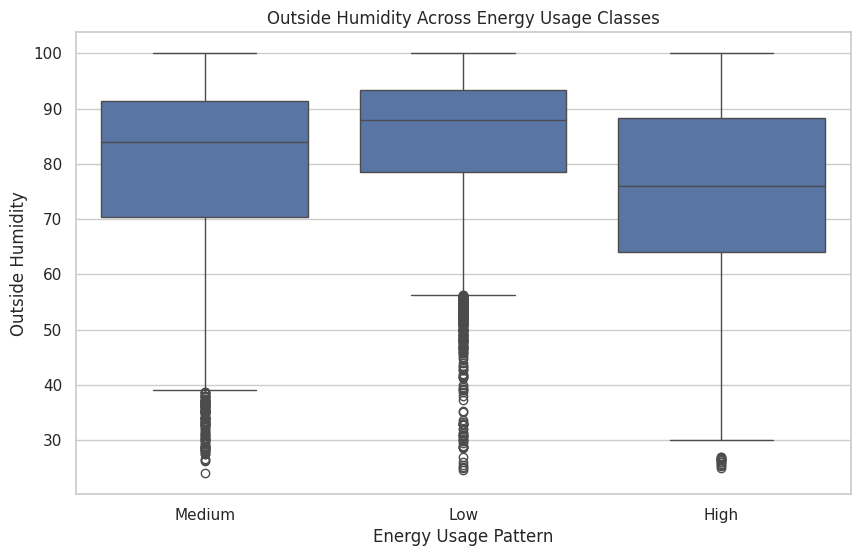

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Energy_Label",
    y="RH_out"
)

plt.xlabel(
    "Energy Usage Pattern"
)

plt.ylabel(
    "Outside Humidity"
)

plt.title(
    "Outside Humidity Across Energy Usage Classes"
)

plt.show()

## Select ML Features

In [ ]:
features = [
    "lights",

    "T1", "RH_1",
    "T2", "RH_2",
    "T3", "RH_3",
    "T4", "RH_4",
    "T5", "RH_5",
    "T6", "RH_6",
    "T7", "RH_7",
    "T8", "RH_8",
    "T9", "RH_9",

    "T_out",
    "Press_mm_hg",
    "RH_out",
    "Windspeed",
    "Visibility",
    "Tdewpoint",

    "hour",
    "day_of_week",
    "is_weekend"
]

X = df[features].copy()

y = df["Energy_Class"].values

print("Number of features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of features: 28
X shape: (19735, 28)
y shape: (19735,)


## Check X and y

In [ ]:
print("Feature matrix:")
display(X.head())

print("\nTarget:")
print(y[:20])

Feature matrix:


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day_of_week,is_weekend
0,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,17,0,0
1,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,17,0,0
2,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,17,0,0
3,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,17,0,0
4,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,17,0,0



Target:
[1 1 0 0 1 0 1 1 1 1 2 2 2 2 2 2 2 1 1 2]


## Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 15788
Testing samples: 3947


## Feature Scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print(
    "Feature scaling completed!"
)

Feature scaling completed!


# DECISION TREE FROM SCRATCH

## Entropy

In [ ]:
def entropy(y):

    classes, counts = np.unique(
        y,
        return_counts=True
    )

    probabilities = counts / len(y)

    entropy_value = 0

    for p in probabilities:

        if p > 0:
            entropy_value -= (
                p * np.log2(p)
            )

    return entropy_value


print(
    "Training Entropy:",
    entropy(y_train)
)

Training Entropy: 1.5785018042536993


## Information Gain

In [ ]:
def information_gain(
    parent,
    left,
    right
):

    if len(left) == 0 or len(right) == 0:
        return 0

    parent_entropy = entropy(parent)

    left_weight = (
        len(left) / len(parent)
    )

    right_weight = (
        len(right) / len(parent)
    )

    child_entropy = (
        left_weight * entropy(left)
        +
        right_weight * entropy(right)
    )

    return (
        parent_entropy
        -
        child_entropy
    )

## Tree Node

In [ ]:
class TreeNode:

    def __init__(
        self,
        feature=None,
        threshold=None,
        left=None,
        right=None,
        value=None
    ):

        self.feature = feature
        self.threshold = threshold

        self.left = left
        self.right = right

        self.value = value

## Decision Tree From Scratch

In [ ]:
class DecisionTreeScratch:

    def __init__(
        self,
        max_depth=6,
        min_samples_split=20,
        max_thresholds=15
    ):

        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_thresholds = max_thresholds
        self.root = None

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        self.root = self._build_tree(
            X,
            y,
            depth=0
        )

    def _build_tree(
        self,
        X,
        y,
        depth
    ):

        num_samples = len(y)

        unique_classes = np.unique(y)

        # Stopping conditions

        if (
            depth >= self.max_depth
            or len(unique_classes) == 1
            or num_samples < self.min_samples_split
        ):

            return TreeNode(
                value=self._majority_class(y)
            )

        best_feature = None
        best_threshold = None
        best_gain = -1

        num_features = X.shape[1]

        for feature_index in range(
            num_features
        ):

            values = np.unique(
                X[:, feature_index]
            )

            if len(values) <= 1:
                continue

            # Select limited thresholds
            # to keep training practical

            if len(values) > self.max_thresholds:

                thresholds = np.percentile(
                    values,
                    np.linspace(
                        5,
                        95,
                        self.max_thresholds
                    )
                )

            else:

                thresholds = (
                    values[:-1]
                    +
                    values[1:]
                ) / 2

            for threshold in thresholds:

                left_mask = (
                    X[:, feature_index]
                    <= threshold
                )

                right_mask = ~left_mask

                if (
                    left_mask.sum() == 0
                    or right_mask.sum() == 0
                ):
                    continue

                gain = information_gain(
                    y,
                    y[left_mask],
                    y[right_mask]
                )

                if gain > best_gain:

                    best_gain = gain
                    best_feature = feature_index
                    best_threshold = threshold

        # No useful split

        if best_feature is None:

            return TreeNode(
                value=self._majority_class(y)
            )

        left_mask = (
            X[:, best_feature]
            <= best_threshold
        )

        right_mask = ~left_mask

        left_subtree = self._build_tree(
            X[left_mask],
            y[left_mask],
            depth + 1
        )

        right_subtree = self._build_tree(
            X[right_mask],
            y[right_mask],
            depth + 1
        )

        return TreeNode(
            feature=best_feature,
            threshold=best_threshold,
            left=left_subtree,
            right=right_subtree
        )

    def _majority_class(self, y):

        counter = Counter(y)

        return counter.most_common(1)[0][0]

    def _predict_sample(
        self,
        x,
        node
    ):

        if node.value is not None:

            return node.value

        if (
            x[node.feature]
            <= node.threshold
        ):

            return self._predict_sample(
                x,
                node.left
            )

        else:

            return self._predict_sample(
                x,
                node.right
            )

    def predict(self, X):

        X = np.asarray(X)

        return np.array([
            self._predict_sample(
                x,
                self.root
            )
            for x in X
        ])

## Train Decision Tree

In [ ]:
dt_scratch = DecisionTreeScratch(
    max_depth=6,
    min_samples_split=20,
    max_thresholds=15
)

dt_scratch.fit(
    X_train.values,
    y_train
)

dt_predictions = dt_scratch.predict(
    X_test.values
)

print(
    "Decision Tree training completed!"
)

Decision Tree training completed!


## Decision Tree Evaluation

In [ ]:
dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

dt_precision = precision_score(
    y_test,
    dt_predictions,
    average="weighted"
)

dt_recall = recall_score(
    y_test,
    dt_predictions,
    average="weighted"
)

dt_f1 = f1_score(
    y_test,
    dt_predictions,
    average="weighted"
)

print("DECISION TREE FROM SCRATCH")
print("--------------------------")

print(
    "Accuracy :",
    round(dt_accuracy, 4)
)

print(
    "Precision:",
    round(dt_precision, 4)
)

print(
    "Recall   :",
    round(dt_recall, 4)
)

print(
    "F1 Score :",
    round(dt_f1, 4)
)

DECISION TREE FROM SCRATCH
--------------------------
Accuracy : 0.6167
Precision: 0.6017
Recall   : 0.6167
F1 Score : 0.5956


## Decision Tree Confusion Matrix

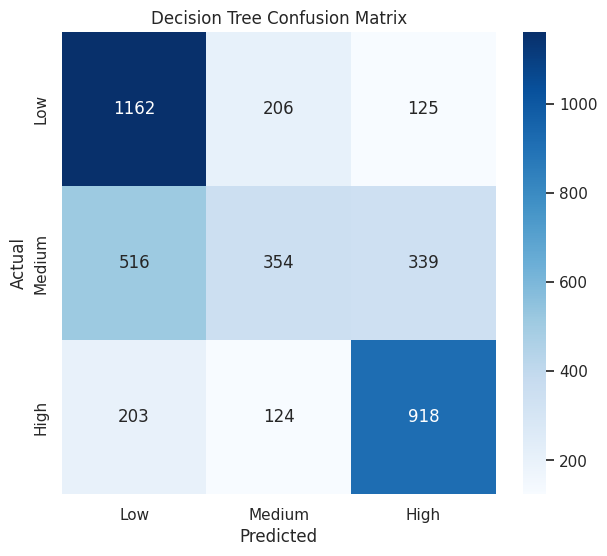

In [ ]:
cm_dt = confusion_matrix(
    y_test,
    dt_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

## Decision Tree

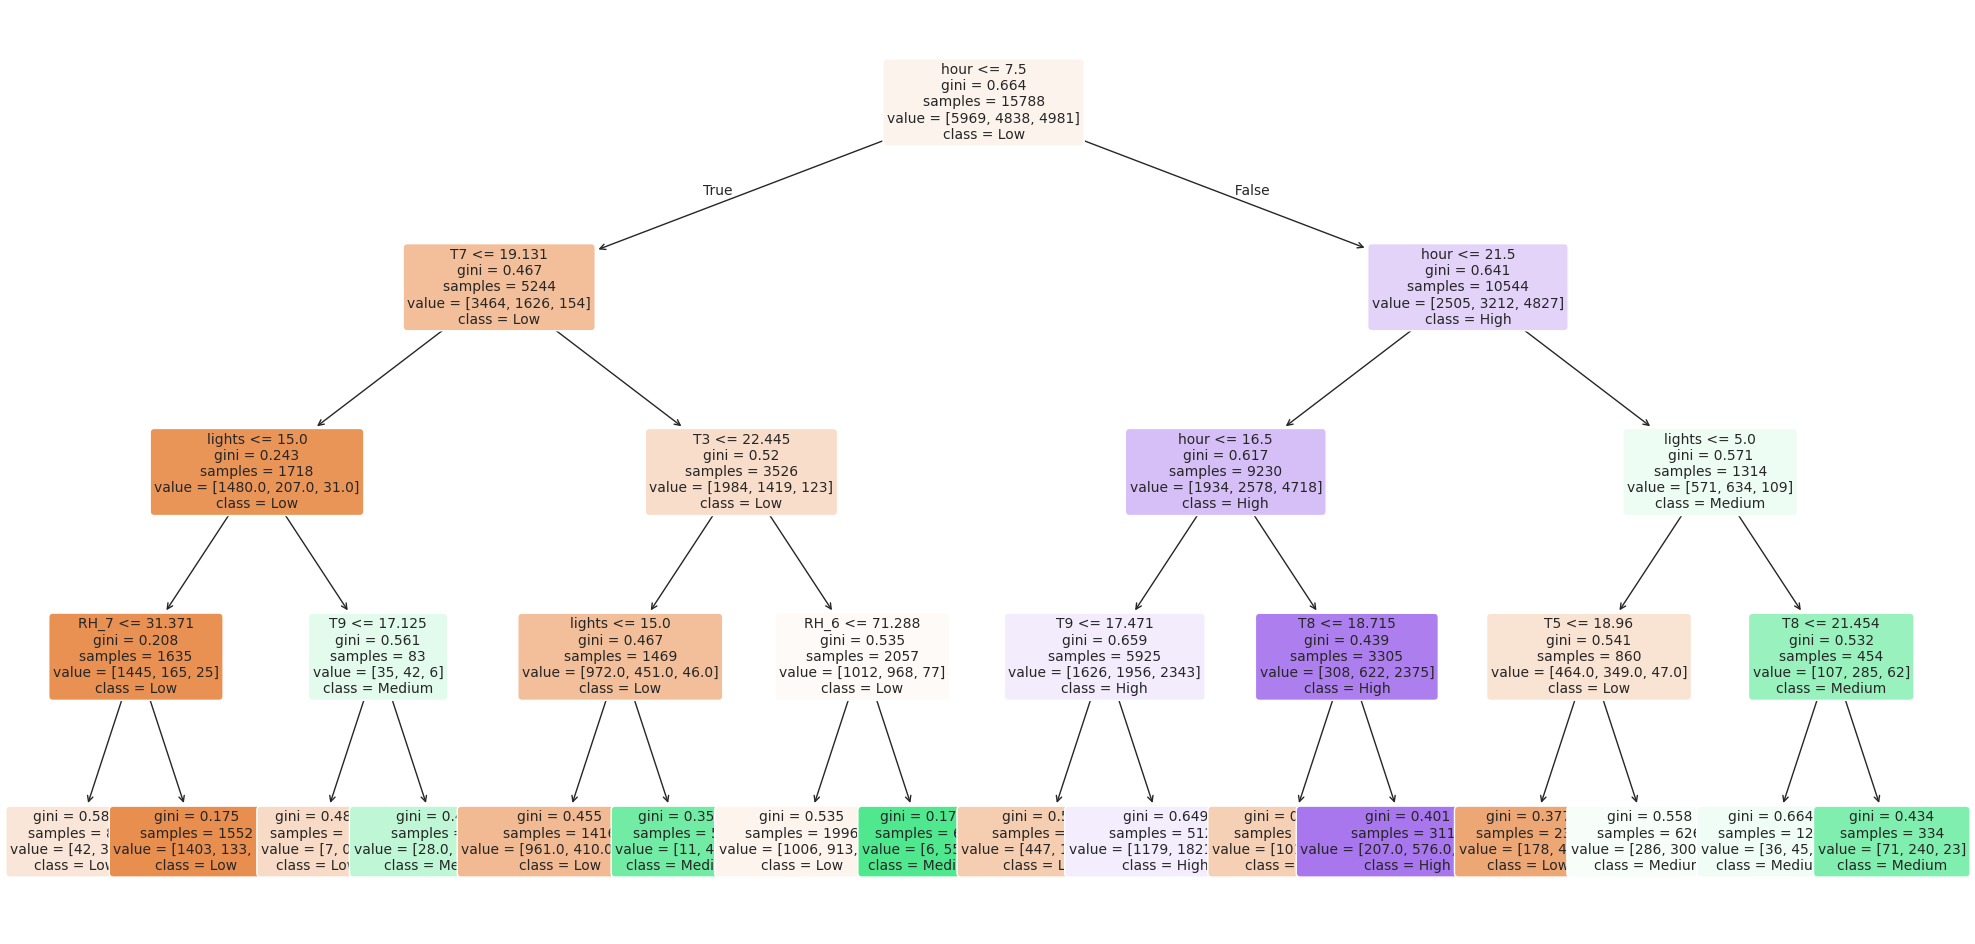

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

dt_model.fit(X_train, y_train)

plt.figure(figsize=(25, 12))

plot_tree(
    dt_model,
    feature_names=features,
    class_names=["Low", "Medium", "High"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

# NAIVE BAYES FROM SCRATCH

## Gaussian Naive Bayes

In [ ]:
class GaussianNaiveBayesScratch:

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        self.classes = np.unique(y)

        self.mean = {}
        self.var = {}
        self.prior = {}

        for c in self.classes:

            X_c = X[y == c]

            self.mean[c] = np.mean(
                X_c,
                axis=0
            )

            self.var[c] = (
                np.var(
                    X_c,
                    axis=0
                )
                + 1e-9
            )

            self.prior[c] = (
                len(X_c) / len(X)
            )

    def _log_gaussian_probability(
        self,
        x,
        mean,
        var
    ):

        return (
            -0.5
            * np.log(
                2 * np.pi * var
            )
            -
            (
                (x - mean) ** 2
                /
                (2 * var)
            )
        )

    def _predict_sample(self, x):

        probabilities = {}

        for c in self.classes:

            log_likelihood = np.sum(
                self._log_gaussian_probability(
                    x,
                    self.mean[c],
                    self.var[c]
                )
            )

            log_prior = np.log(
                self.prior[c]
            )

            probabilities[c] = (
                log_prior
                +
                log_likelihood
            )

        return max(
            probabilities,
            key=probabilities.get
        )

    def predict(self, X):

        X = np.asarray(X)

        return np.array([
            self._predict_sample(x)
            for x in X
        ])

## Train Naive Bayes

In [ ]:
nb_scratch = GaussianNaiveBayesScratch()

nb_scratch.fit(
    X_train_scaled,
    y_train
)

nb_predictions = nb_scratch.predict(
    X_test_scaled
)

print(
    "Naive Bayes training completed!"
)

Naive Bayes training completed!


## Naive Bayes Evaluation

In [ ]:
nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

nb_precision = precision_score(
    y_test,
    nb_predictions,
    average="weighted"
)

nb_recall = recall_score(
    y_test,
    nb_predictions,
    average="weighted"
)

nb_f1 = f1_score(
    y_test,
    nb_predictions,
    average="weighted"
)

print("NAIVE BAYES FROM SCRATCH")
print("------------------------")

print(
    "Accuracy :",
    round(nb_accuracy, 4)
)

print(
    "Precision:",
    round(nb_precision, 4)
)

print(
    "Recall   :",
    round(nb_recall, 4)
)

print(
    "F1 Score :",
    round(nb_f1, 4)
)

NAIVE BAYES FROM SCRATCH
------------------------
Accuracy : 0.532
Precision: 0.5242
Recall   : 0.532
F1 Score : 0.5222


## Naive Bayes Confusion Matrix

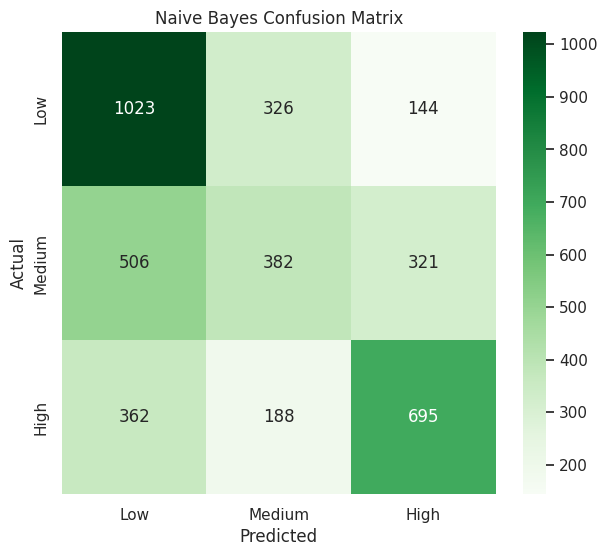

In [ ]:
cm_nb = confusion_matrix(
    y_test,
    nb_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Naive Bayes Confusion Matrix"
)

plt.show()

# LOGISTIC REGRESSION FROM SCRATCH

## Softmax

In [ ]:
def softmax(z):

    z = z - np.max(
        z,
        axis=1,
        keepdims=True
    )

    exp_z = np.exp(z)

    return (
        exp_z
        /
        np.sum(
            exp_z,
            axis=1,
            keepdims=True
        )
    )

## Logistic Regression Class

In [ ]:
class LogisticRegressionScratch:

    def __init__(
        self,
        learning_rate=0.05,
        epochs=1000
    ):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.loss_history = []

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        self.classes = np.unique(y)

        n_samples = X.shape[0]
        n_features = X.shape[1]
        n_classes = len(self.classes)

        # Add bias column

        X_bias = np.c_[
            np.ones(n_samples),
            X
        ]

        self.weights = np.zeros(
            (
                n_features + 1,
                n_classes
            )
        )

        # One-hot encoding

        Y = np.zeros(
            (
                n_samples,
                n_classes
            )
        )

        for i, c in enumerate(
            self.classes
        ):

            Y[:, i] = (
                y == c
            ).astype(int)

        # Gradient descent

        for epoch in range(
            self.epochs
        ):

            scores = (
                X_bias
                @
                self.weights
            )

            probabilities = softmax(
                scores
            )

            # Cross entropy loss

            loss = -np.mean(
                np.sum(
                    Y
                    *
                    np.log(
                        probabilities
                        + 1e-9
                    ),
                    axis=1
                )
            )

            self.loss_history.append(
                loss
            )

            # Gradient

            gradient = (
                X_bias.T
                @
                (
                    probabilities
                    - Y
                )
            ) / n_samples

            # Weight update

            self.weights -= (
                self.learning_rate
                *
                gradient
            )

    def predict_proba(self, X):

        X = np.asarray(X)

        X_bias = np.c_[
            np.ones(len(X)),
            X
        ]

        scores = (
            X_bias
            @
            self.weights
        )

        return softmax(scores)

    def predict(self, X):

        probabilities = (
            self.predict_proba(X)
        )

        indices = np.argmax(
            probabilities,
            axis=1
        )

        return self.classes[
            indices
        ]

## Train Logistic Regression

In [ ]:
lr_scratch = LogisticRegressionScratch(
    learning_rate=0.05,
    epochs=1000
)

lr_scratch.fit(
    X_train_scaled,
    y_train
)

lr_predictions = lr_scratch.predict(
    X_test_scaled
)

print(
    "Logistic Regression training completed!"
)

Logistic Regression training completed!


## Logistic Regression Loss Graph

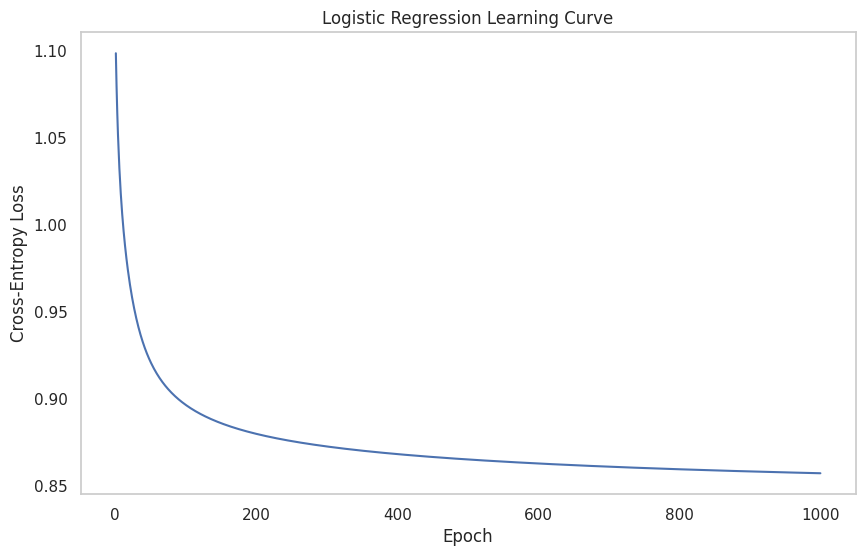

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(
        1,
        len(
            lr_scratch.loss_history
        ) + 1
    ),
    lr_scratch.loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.title(
    "Logistic Regression Learning Curve"
)

plt.grid()

plt.show()

## Logistic Regression Evaluation

In [ ]:
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    average="weighted"
)

lr_recall = recall_score(
    y_test,
    lr_predictions,
    average="weighted"
)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    average="weighted"
)

print("LOGISTIC REGRESSION FROM SCRATCH")
print("--------------------------------")

print(
    "Accuracy :",
    round(lr_accuracy, 4)
)

print(
    "Precision:",
    round(lr_precision, 4)
)

print(
    "Recall   :",
    round(lr_recall, 4)
)

print(
    "F1 Score :",
    round(lr_f1, 4)
)

LOGISTIC REGRESSION FROM SCRATCH
--------------------------------
Accuracy : 0.5822
Precision: 0.5637
Recall   : 0.5822
F1 Score : 0.5623


## Logistic Regression Confusion Matrix

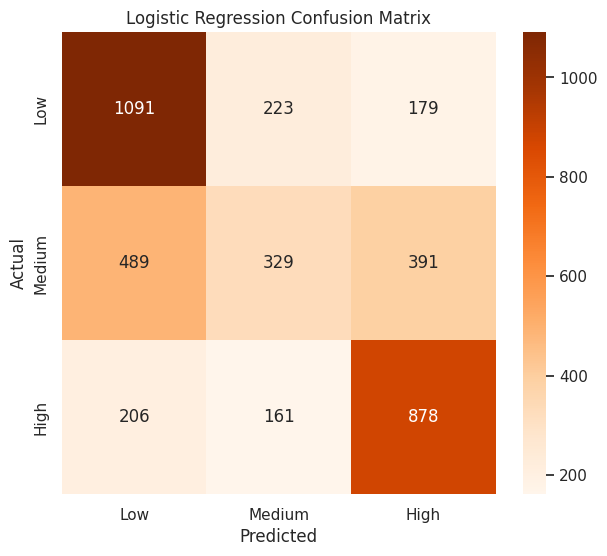

In [ ]:
cm_lr = confusion_matrix(
    y_test,
    lr_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

## Model Results Table

In [ ]:
results = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Naive Bayes",
        "Logistic Regression"
    ],

    "Accuracy": [
        dt_accuracy,
        nb_accuracy,
        lr_accuracy
    ],

    "Precision": [
        dt_precision,
        nb_precision,
        lr_precision
    ],

    "Recall": [
        dt_recall,
        nb_recall,
        lr_recall
    ],

    "F1 Score": [
        dt_f1,
        nb_f1,
        lr_f1
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.6167,0.6017,0.6167,0.5956
1,Naive Bayes,0.5320,0.5242,0.5320,0.5222
2,Logistic Regression,0.5822,0.5637,0.5822,0.5623


## Accuracy Comparison

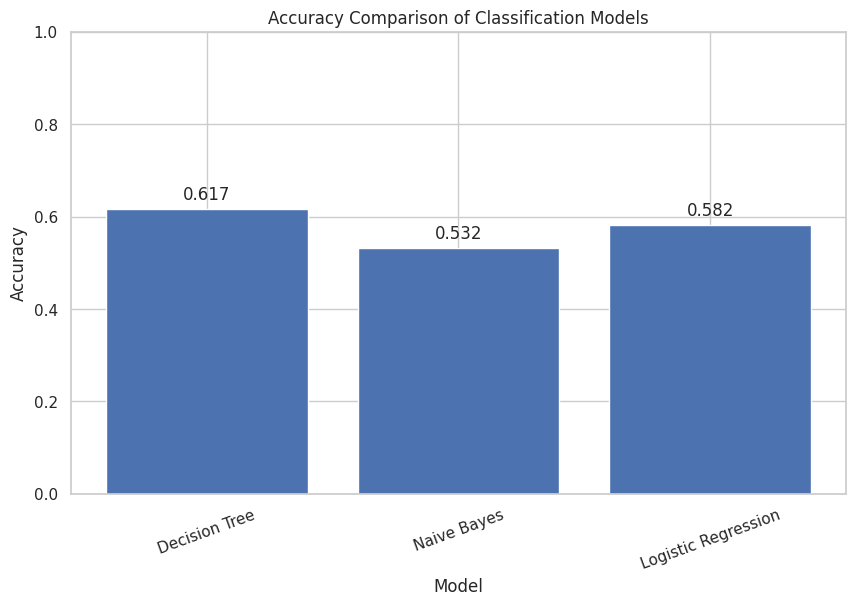

In [ ]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")

plt.title(
    "Accuracy Comparison of Classification Models"
)

plt.ylim(0, 1)

plt.xticks(rotation=20)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.02,
        f"{height:.3f}",
        ha="center"
    )

plt.show()

## All Metrics Comparison

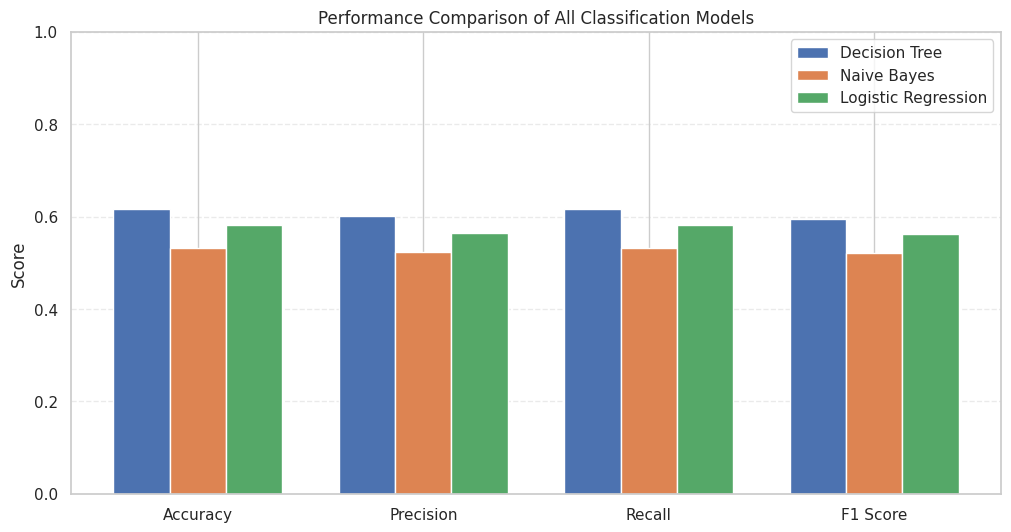

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

x = np.arange(
    len(metrics)
)

width = 0.25

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width,
    results.iloc[0][metrics],
    width,
    label="Decision Tree"
)

plt.bar(
    x,
    results.iloc[1][metrics],
    width,
    label="Naive Bayes"
)

plt.bar(
    x + width,
    results.iloc[2][metrics],
    width,
    label="Logistic Regression"
)

plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")

plt.title(
    "Performance Comparison of All Classification Models"
)

plt.ylim(0, 1)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.show()

## Performance Heatmap

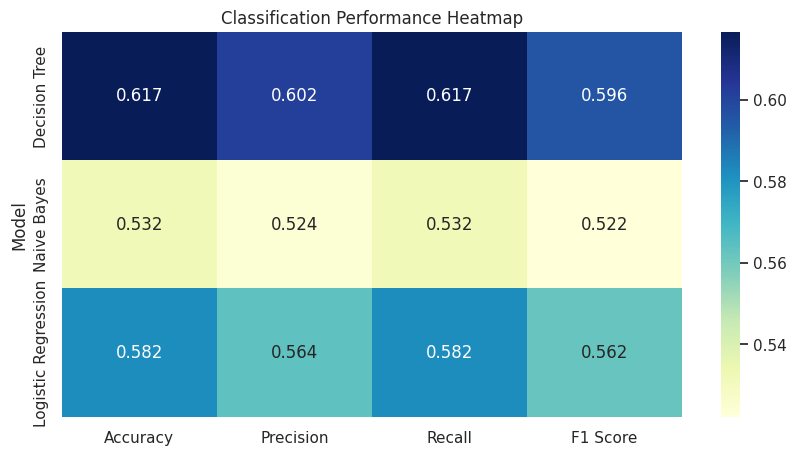

In [ ]:
metric_table = results.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

plt.figure(figsize=(10, 5))

sns.heatmap(
    metric_table,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.title(
    "Classification Performance Heatmap"
)

plt.show()

## Three Confusion Matrices Together

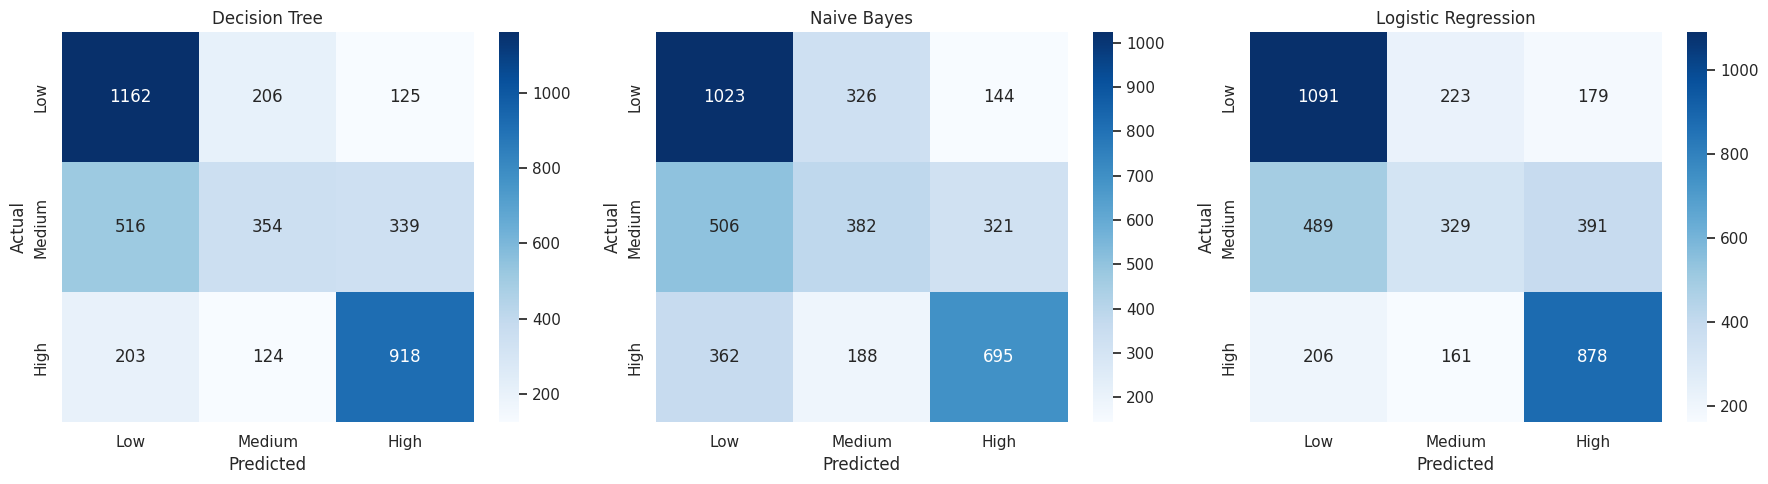

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

predictions = [
    dt_predictions,
    nb_predictions,
    lr_predictions
]

model_names = [
    "Decision Tree",
    "Naive Bayes",
    "Logistic Regression"
]

for ax, pred, name in zip(
    axes,
    predictions,
    model_names
):

    cm = confusion_matrix(
        y_test,
        pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        cmap="Blues",
        xticklabels=[
            "Low",
            "Medium",
            "High"
        ],
        yticklabels=[
            "Low",
            "Medium",
            "High"
        ]
    )

    ax.set_title(name)

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

plt.tight_layout()

plt.show()

## Classification Reports

In [ ]:
print("=" * 60)
print("DECISION TREE")
print("=" * 60)

print(
    classification_report(
        y_test,
        dt_predictions,
        target_names=[
            "Low",
            "Medium",
            "High"
        ]
    )
)


print("=" * 60)
print("NAIVE BAYES")
print("=" * 60)

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=[
            "Low",
            "Medium",
            "High"
        ]
    )
)


print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=[
            "Low",
            "Medium",
            "High"
        ]
    )
)

DECISION TREE
              precision    recall  f1-score   support

         Low       0.62      0.78      0.69      1493
      Medium       0.52      0.29      0.37      1209
        High       0.66      0.74      0.70      1245

    accuracy                           0.62      3947
   macro avg       0.60      0.60      0.59      3947
weighted avg       0.60      0.62      0.60      3947

NAIVE BAYES
              precision    recall  f1-score   support

         Low       0.54      0.69      0.60      1493
      Medium       0.43      0.32      0.36      1209
        High       0.60      0.56      0.58      1245

    accuracy                           0.53      3947
   macro avg       0.52      0.52      0.52      3947
weighted avg       0.52      0.53      0.52      3947

LOGISTIC REGRESSION
              precision    recall  f1-score   support

         Low       0.61      0.73      0.67      1493
      Medium       0.46      0.27      0.34      1209
        High       0.61      

## Actual vs Predicted

In [ ]:
comparison = pd.DataFrame({

    "Actual": y_test,

    "Decision_Tree": dt_predictions,

    "Naive_Bayes": nb_predictions,

    "Logistic_Regression": lr_predictions

})

comparison["Actual_Label"] = (
    comparison["Actual"]
    .map(class_names)
)

comparison.head(20)

,Actual,Decision_Tree,Naive_Bayes,Logistic_Regression,Actual_Label
0,2,2,2,2,High
1,0,0,0,0,Low
2,1,1,1,0,Medium
3,1,1,1,1,Medium
4,2,1,1,0,High
5,2,1,2,2,High
6,1,0,0,0,Medium
7,2,2,1,1,High
8,0,0,0,0,Low
9,0,0,0,0,Low


## High Consumption Hours

In [ ]:
high_usage = df[
    df["Energy_Class"] == 2
]

print(
    "Number of high-consumption records:",
    len(high_usage)
)

Number of high-consumption records: 6226


## High Consumption by Hour

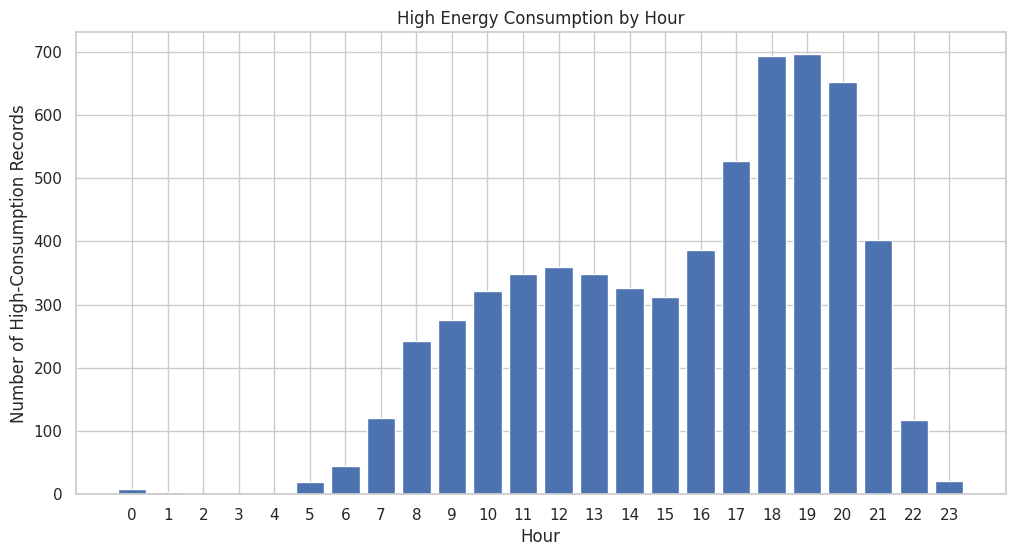

In [ ]:
high_usage_hour = (
    high_usage
    .groupby("hour")
    .size()
)

plt.figure(figsize=(12, 6))

plt.bar(
    high_usage_hour.index,
    high_usage_hour.values
)

plt.xlabel("Hour")
plt.ylabel(
    "Number of High-Consumption Records"
)

plt.title(
    "High Energy Consumption by Hour"
)

plt.xticks(range(24))

plt.show()

## Percentage of High Consumption by Hour

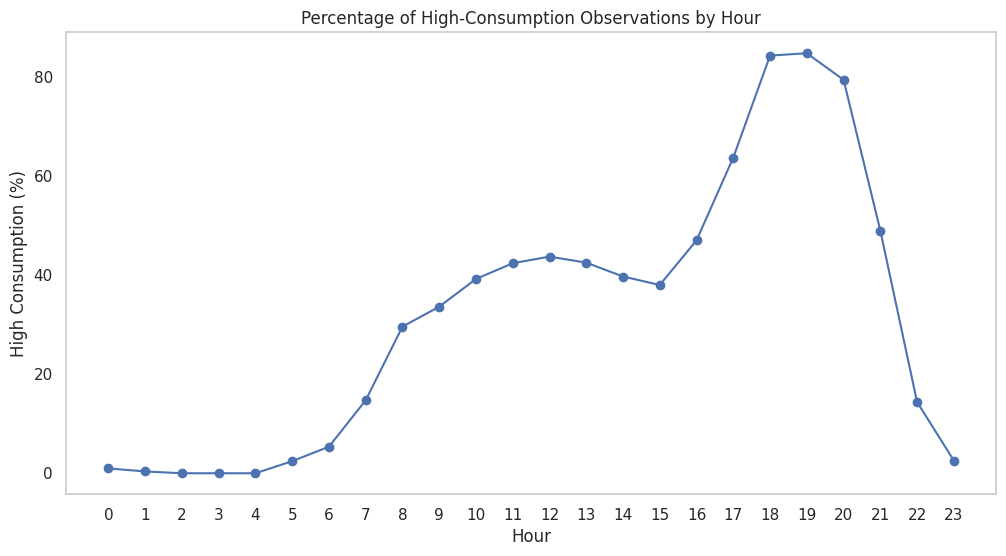

In [ ]:
total_hour = (
    df.groupby("hour")
      .size()
)

high_hour = (
    df[
        df["Energy_Class"] == 2
    ]
    .groupby("hour")
    .size()
)

high_percentage = (
    high_hour
    /
    total_hour
    *
    100
).fillna(0)

plt.figure(figsize=(12, 6))

plt.plot(
    high_percentage.index,
    high_percentage.values,
    marker="o"
)

plt.xlabel("Hour")

plt.ylabel(
    "High Consumption (%)"
)

plt.title(
    "Percentage of High-Consumption Observations by Hour"
)

plt.xticks(range(24))

plt.grid()

plt.show()

## Weekday vs Weekend by Hour

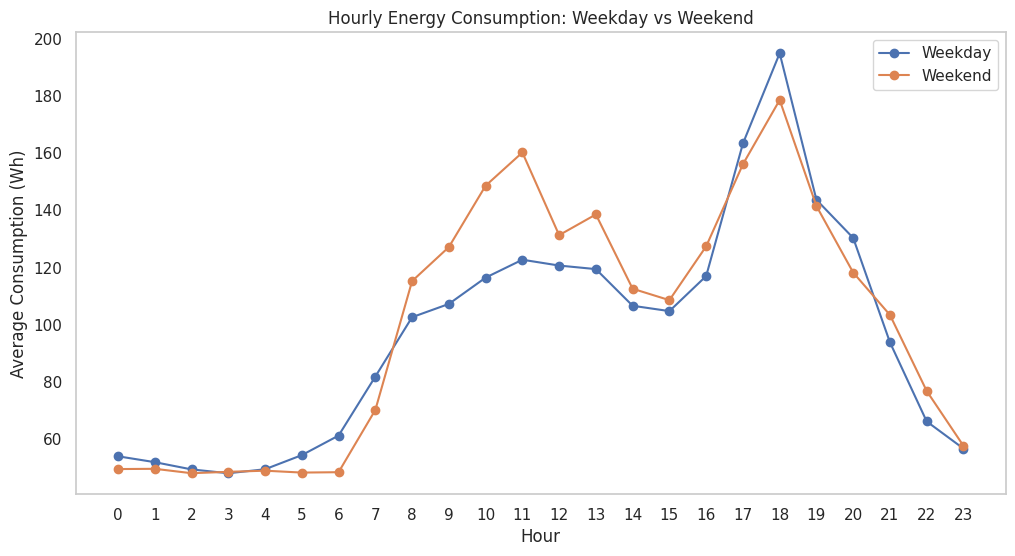

In [ ]:
hour_weekend = df.pivot_table(
    index="hour",
    columns="is_weekend",
    values="Appliances",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

plt.plot(
    hour_weekend.index,
    hour_weekend[0],
    marker="o",
    label="Weekday"
)

plt.plot(
    hour_weekend.index,
    hour_weekend[1],
    marker="o",
    label="Weekend"
)

plt.xlabel("Hour")

plt.ylabel(
    "Average Consumption (Wh)"
)

plt.title(
    "Hourly Energy Consumption: Weekday vs Weekend"
)

plt.xticks(range(24))

plt.legend()

plt.grid()

plt.show()

## Energy Consumption Summary

In [ ]:
hour_summary = df.groupby(
    "hour"
)["Appliances"].agg(
    [
        "mean",
        "median",
        "min",
        "max"
    ]
)

hour_summary

,mean,median,min,max
hour,,,,
0,52.785888,50.0,20,380
1,51.326034,50.0,20,380
2,49.075426,50.0,20,80
3,48.236010,50.0,20,80
4,49.355231,50.0,10,80
5,52.737226,50.0,20,380
6,57.712895,50.0,10,650
7,78.649635,60.0,20,700
8,106.143552,60.0,10,850


## Identify High Usage Hours

In [ ]:
overall_mean = df[
    "Appliances"
].mean()

high_usage_hours = hour_summary[
    hour_summary["mean"]
    >
    overall_mean
]

print(
    "Overall average consumption:",
    overall_mean
)

print(
    "\nHours with above-average consumption:"
)

print(
    high_usage_hours
)

Overall average consumption: 97.6949581960983

Hours with above-average consumption:
            mean  median  min   max
hour                               
8     106.143552    60.0   10   850
9     112.785888    70.0   10   820
10    125.377129    70.0   20   860
11    133.126521    70.0   10   780
12    123.637470    80.0   20   790
13    124.744526    80.0   10   750
14    108.284672    70.0   20   710
15    105.827251    80.0   20   900
16    119.902676    80.0   20   850
17    161.352657   100.0   20   910
18    190.364520   120.0   20  1080
19    143.065693   110.0   20   890
20    126.982968   110.0   20   740


## Optimization Recommendations

In [ ]:
highest_hour = (
    hourly
    .idxmax()
)

highest_hour_value = (
    hourly
    .max()
)

lowest_hour = (
    hourly
    .idxmin()
)

lowest_hour_value = (
    hourly
    .min()
)

print("=" * 60)
print("SMART HOME ENERGY OPTIMIZATION ANALYSIS")
print("=" * 60)

print(
    f"\nHighest average consumption hour: "
    f"{highest_hour}:00"
)

print(
    f"Consumption: "
    f"{highest_hour_value:.2f} Wh"
)

print(
    f"\nLowest average consumption hour: "
    f"{lowest_hour}:00"
)

print(
    f"Consumption: "
    f"{lowest_hour_value:.2f} Wh"
)

print("\nRecommendations:")
print(
    "1. Monitor appliance usage during high-consumption hours."
)

print(
    "2. Avoid unnecessary simultaneous operation of "
    "high-energy appliances."
)

print(
    "3. Switch off appliances when they are not required."
)

print(
    "4. Use smart scheduling for energy-intensive appliances."
)

print(
    "5. Monitor heating and cooling usage because "
    "environmental conditions can affect consumption."
)

print(
    "6. Use energy-efficient appliances where possible."
)

print(
    "7. Continuously monitor household energy patterns "
    "to detect unusual high consumption."
)

SMART HOME ENERGY OPTIMIZATION ANALYSIS

Highest average consumption hour: 18:00
Consumption: 190.36 Wh

Lowest average consumption hour: 3:00
Consumption: 48.24 Wh

Recommendations:
1. Monitor appliance usage during high-consumption hours.
2. Avoid unnecessary simultaneous operation of high-energy appliances.
3. Switch off appliances when they are not required.
4. Use smart scheduling for energy-intensive appliances.
5. Monitor heating and cooling usage because environmental conditions can affect consumption.
6. Use energy-efficient appliances where possible.
7. Continuously monitor household energy patterns to detect unusual high consumption.


## Prediction Function

In [ ]:
def predict_energy_class(
    model,
    input_values
):

    input_array = np.array(
        input_values
    ).reshape(1, -1)

    input_scaled = scaler.transform(
        input_array
    )

    prediction = model.predict(
        input_scaled
    )[0]

    return prediction

## Test Prediction Using Existing Data

In [ ]:
sample = X_test.iloc[
    0
].values

actual_class = y_test[0]

predicted_class = predict_energy_class(
    lr_scratch,
    sample
)

print(
    "Actual Energy Pattern:",
    class_names[actual_class]
)

print(
    "Predicted Energy Pattern:",
    class_names[predicted_class]
)

Actual Energy Pattern: High
Predicted Energy Pattern: High


## Interactive User Input

In [ ]:
print("=" * 60)
print("SMART HOME ENERGY USAGE PREDICTION")
print("=" * 60)

print(
    "\nEnter values for the following features."
)

input_values = []

for feature in features:

    value = float(
        input(
            f"Enter {feature}: "
        )
    )

    input_values.append(value)


prediction = predict_energy_class(
    lr_scratch,
    input_values
)

print("\n" + "=" * 60)

print(
    "Predicted Energy Usage Pattern:",
    class_names[prediction]
)

print("=" * 60)

SMART HOME ENERGY USAGE PREDICTION

Enter values for the following features.
Enter lights: 6
Enter T1: 35
Enter RH_1: 21
Enter T2: 56
Enter RH_2: 32
Enter T3: 45
Enter RH_3: 14
Enter T4: 65
Enter RH_4: 78
Enter T5: 27
Enter RH_5: 21
Enter T6: 78
Enter RH_6: 32
Enter T7: 78
Enter RH_7: 21
Enter T8: 89
Enter RH_8: 21
Enter T9: 45
Enter RH_9: 26
Enter T_out: 40
Enter Press_mm_hg: 172
Enter RH_out: 54
Enter Windspeed: 75
Enter Visibility: 86
Enter Tdewpoint: 43
Enter hour: 8
Enter day_of_week: 6
Enter is_weekend: 1

Predicted Energy Usage Pattern: High


## Optimization Recommendation for Prediction

In [ ]:
def optimization_recommendation(
    prediction
):

    if prediction == 0:

        return """
LOW CONSUMPTION

The predicted energy usage pattern is LOW.

Recommendations:
• Continue monitoring consumption.
• Maintain efficient appliance usage.
• Avoid unnecessary standby power.
• Continue using energy-efficient appliances.
"""

    elif prediction == 1:

        return """
MEDIUM CONSUMPTION

The predicted energy usage pattern is MEDIUM.

Recommendations:
• Reduce unnecessary appliance usage.
• Switch off unused devices.
• Monitor lighting consumption.
• Schedule energy-intensive appliances efficiently.
• Monitor heating and cooling usage.
"""

    else:

        return """
HIGH CONSUMPTION

The predicted energy usage pattern is HIGH.

Recommendations:
• Identify high-consumption appliances.
• Avoid simultaneous operation of multiple
  high-energy appliances.
• Monitor peak-consumption hours.
• Reduce unnecessary heating/cooling usage.
• Use smart scheduling.
• Check appliances for inefficient operation.
"""


print(
    optimization_recommendation(
        prediction
    )
)


HIGH CONSUMPTION

The predicted energy usage pattern is HIGH.

Recommendations:
• Identify high-consumption appliances.
• Avoid simultaneous operation of multiple
  high-energy appliances.
• Monitor peak-consumption hours.
• Reduce unnecessary heating/cooling usage.
• Use smart scheduling.
• Check appliances for inefficient operation.



## Final Model Comparison

In [ ]:
print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    results.round(4)
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.6167,0.6017,0.6167,0.5956
1,Naive Bayes,0.5320,0.5242,0.5320,0.5222
2,Logistic Regression,0.5822,0.5637,0.5822,0.5623


## Conclusion

The project successfully classified smart-home energy consumption into three categories: Low, Medium, and High consumption.

The UCI Appliances Energy Prediction dataset was used because it contains appliance energy consumption along with indoor temperature, humidity, outdoor weather conditions, and time-related information.

Extensive Exploratory Data Analysis was performed to understand the characteristics of household energy consumption. Histograms, KDE plots, box plots, scatter plots, pair plots, line graphs, bar charts, and correlation heatmaps were used to identify important patterns and relationships in the data.

Time-based analysis was performed using hour, day of the week, weekday/weekend status, and time periods. Environmental factors such as temperature, humidity, wind speed, and dew point were also analyzed in relation to energy consumption.

The continuous appliance energy consumption value was converted into three classification categories:

* Low Consumption
* Medium Consumption
* High Consumption

Three machine learning algorithms were implemented from scratch:

1. Decision Tree using entropy and information gain
2. Gaussian Naive Bayes using probability distributions
3. Multiclass Logistic Regression using softmax, cross-entropy loss, and gradient descent

The models were evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. Graphical comparisons were also performed to understand the relative performance of the models.

The analysis of high-consumption periods provides useful information for smart-home energy optimization. High-consumption hours can be monitored, energy-intensive appliances can be scheduled more efficiently, and unnecessary appliance usage can be reduced.

The final prediction system allows new household conditions to be entered and classifies the expected energy usage as Low, Medium, or High.

Therefore, machine learning can be used to transform raw smart-home energy data into meaningful consumption patterns and support data-driven energy-management strategies.
